In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import warnings

# ============================================================
# NOTEBOOK 07: RESOURCE BENCHMARKING
# Independent setup - does not rerun previous experiments
# ============================================================

# Locate project root
cwd = Path.cwd()

if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

# Project directories
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"

TABLE_DIR = RESULTS_DIR / "tables"
FIGURE_DIR = RESULTS_DIR / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Reproducibility settings
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Existing benchmark configuration
NV = 32
K_MODE = 0.5
DT = 0.001

print("=" * 60)
print("NOTEBOOK 07: RESOURCE BENCHMARKING")
print("=" * 60)

print(f"\nProject root: {PROJECT_ROOT}")
print(f"Results directory: {RESULTS_DIR}")

# Discover existing CSV datasets
if TABLE_DIR.exists():
    csv_files = sorted(TABLE_DIR.glob("*.csv"))
else:
    csv_files = []

print("\nEXISTING CSV FILES")
print("-" * 40)

if csv_files:
    for file in csv_files:
        try:
            df = pd.read_csv(file)
            print(
                f"{file.name:<45} "
                f"{df.shape[0]} rows x {df.shape[1]} columns"
            )
        except Exception as exc:
            print(f"{file.name}: Could not inspect ({exc})")
else:
    print("No CSV files found in results/tables.")

# Verify the two direct-comparison datasets
required_files = [
    "HHL_VQLS_direct_comparison.csv",
    "HHL_VQLS_solution_vectors.csv"
]

print("\nDIRECT COMPARISON DATASETS")
print("-" * 40)

for filename in required_files:
    path = TABLE_DIR / filename
    if path.exists():
        print(f"[FOUND] {filename}")
    else:
        print(f"[MISSING] {filename}")

print("\nOUTPUT DIRECTORIES")
print("-" * 40)
print(f"Tables:  {TABLE_DIR}")
print(f"Figures: {FIGURE_DIR}")

print("\nSetup completed. No previous experiments were rerun.")


NOTEBOOK 07: RESOURCE BENCHMARKING

Project root: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson
Results directory: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results

EXISTING CSV FILES
----------------------------------------
chebyshev_coefficient_precision.csv           84 rows x 7 columns
chebyshev_node_vs_uniform_fit.csv             48 rows x 6 columns
chebyshev_state_approximation.csv             65 rows x 4 columns
continuous_domain_polynomial_validation.csv   12 rows x 6 columns
corrected_landau_damping_fit.csv              1 rows x 9 columns
corrected_landau_envelope_fit.csv             1 rows x 7 columns
corrected_landau_envelope_peaks.csv           8 rows x 2 columns
corrected_landau_field_evolution.csv          20001 rows x 4 columns
corrected_operator_eigenvalue_resolution.csv  5 rows x 4 columns
corrected_quantum_matrix_benchmark.csv        4 rows x 15 columns
derivative_approximation_damping_rates.csv    4 rows x 5 columns
deri

In [2]:

# ============================================================
# CELL 2: LOAD EXISTING HHL AND VQLS RESULTS
# ============================================================

# Load benchmark datasets
matrix_df = pd.read_csv(
    TABLE_DIR / "corrected_quantum_matrix_benchmark.csv"
)

hhl_df = pd.read_csv(
    TABLE_DIR / "ideal_spectral_HHL_benchmark.csv"
)

vqls_df = pd.read_csv(
    TABLE_DIR / "VQLS_extended_seed_results.csv"
)

vqls_summary_df = pd.read_csv(
    TABLE_DIR / "VQLS_extended_summary.csv"
)

vqls_parameters_df = pd.read_csv(
    TABLE_DIR / "VQLS_extended_parameters.csv"
)

vqls_vectors_df = pd.read_csv(
    TABLE_DIR / "VQLS_extended_solution_vectors.csv"
)

direct_comparison_df = pd.read_csv(
    TABLE_DIR / "HHL_VQLS_direct_comparison.csv"
)

direct_vectors_df = pd.read_csv(
    TABLE_DIR / "HHL_VQLS_solution_vectors.csv"
)

# ------------------------------------------------------------
# Display dataset dimensions
# ------------------------------------------------------------

datasets = {
    "Matrix benchmark": matrix_df,
    "Ideal HHL benchmark": hhl_df,
    "VQLS seed results": vqls_df,
    "VQLS summary": vqls_summary_df,
    "VQLS parameters": vqls_parameters_df,
    "VQLS solution vectors": vqls_vectors_df,
    "Direct comparison": direct_comparison_df,
    "Direct solution vectors": direct_vectors_df
}

print("LOADED DATASETS")
print("=" * 65)

for name, dataframe in datasets.items():

    print(
        f"{name:<30} "
        f"{dataframe.shape[0]:>6} rows | "
        f"{dataframe.shape[1]:>3} columns"
    )

# ------------------------------------------------------------
# Inspect available columns
# ------------------------------------------------------------

print("\nAVAILABLE COLUMNS")
print("=" * 65)

for name, dataframe in datasets.items():

    print(f"\n{name}:")
    print(list(dataframe.columns))

# ------------------------------------------------------------
# Basic structural validation
# ------------------------------------------------------------

assert len(matrix_df) == 4
assert len(vqls_df) == 10
assert len(vqls_summary_df) == 2
assert len(vqls_vectors_df) == 320
assert len(direct_comparison_df) == 2
assert len(direct_vectors_df) == 32

assert np.isfinite(
    matrix_df.select_dtypes(include=np.number).to_numpy()
).all()

assert np.isfinite(
    vqls_df.select_dtypes(include=np.number).to_numpy()
).all()

print("\nStructural and numerical checks passed.")


LOADED DATASETS
Matrix benchmark                    4 rows |  15 columns
Ideal HHL benchmark                 4 rows |  13 columns
VQLS seed results                  10 rows |  13 columns
VQLS summary                        2 rows |  10 columns
VQLS parameters                    10 rows |  42 columns
VQLS solution vectors             320 rows |   8 columns
Direct comparison                   2 rows |  13 columns
Direct solution vectors            32 rows |   7 columns

AVAILABLE COLUMNS

Matrix benchmark:
['Nv', 'k', 'dt', 'condition_A', 'condition_H', 'alpha_LCU', 'alpha_over_norm_A', 'matrix_reconstruction_error', 'block_encoding_error', 'unitarity_error_Frobenius', 'Hermitian_dilation_error', 'system_qubits', 'total_register_qubits', 'full_unitary_dimension', 'dense_unitary_storage_MiB']

Ideal HHL benchmark:
['Nv', 'condition_A', 'condition_H', 'minimum_absolute_eigenvalue', 'postselection_success_probability', 'full_state_fidelity', 'lower_block_fidelity', 'upper_block_leakage', 'l

In [5]:

# ============================================================
# CELL 3 — EXPORT DIAGNOSTIC TABLES AND CONSISTENCY REPORT
# Independent of results_dir from previous cells
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# Reconstruct the project results path
project_root = Path(
    r"C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson"
)

results_dir = project_root / "results"
diagnostics_dir = results_dir / "diagnostics"
diagnostics_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Prepare diagnostic tables
# ------------------------------------------------------------

diagnostic_tables = {
    "01_matrix_benchmark.csv": matrix_df,
    "02_ideal_HHL_benchmark.csv": hhl_df,
    "03_VQLS_summary.csv": vqls_summary_df,
    "04_VQLS_seed_results.csv": vqls_df,
    "05_direct_HHL_VQLS_comparison.csv": direct_comparison_df,
}

# ------------------------------------------------------------
# 2. Export tables
# ------------------------------------------------------------

for filename, dataframe in diagnostic_tables.items():
    dataframe.to_csv(
        diagnostics_dir / filename,
        index=False
    )

# ------------------------------------------------------------
# 3. Generate consistency report
# ------------------------------------------------------------

matrix_nv = set(matrix_df["Nv"].astype(int))
hhl_nv = set(hhl_df["Nv"].astype(int))

report = [
    "QUANTUM RESOURCE BENCHMARK — DIAGNOSTIC REPORT",
    "=" * 65,
    "\nDATASET DIMENSIONS",
]

for filename, dataframe in diagnostic_tables.items():
    report.append(
        f"{filename}: {dataframe.shape[0]} rows x "
        f"{dataframe.shape[1]} columns"
    )

report.extend([
    "\nMATRIX / HHL CONSISTENCY",
    f"Matrix Nv values: {sorted(matrix_nv)}",
    f"HHL Nv values: {sorted(hhl_nv)}",
    f"Matching Nv sets: {matrix_nv == hhl_nv}",
    "\nHHL FIDELITY",
    f"Minimum: {hhl_df['full_state_fidelity'].min():.12f}",
    f"Maximum: {hhl_df['full_state_fidelity'].max():.12f}",
    "\nVQLS ANSATZ DEPTHS",
    f"{sorted(vqls_summary_df['layers'].astype(int).unique())}",
    "\nDIRECT COMPARISON SOLVERS",
    f"{direct_comparison_df['solver'].astype(str).tolist()}",
    "\nMATRIX CONSTRUCTION ERRORS",
    f"Maximum reconstruction error: "
    f"{matrix_df['matrix_reconstruction_error'].max():.6e}",
    f"Maximum block-encoding error: "
    f"{matrix_df['block_encoding_error'].max():.6e}",
    f"Maximum unitarity error: "
    f"{matrix_df['unitarity_error_Frobenius'].max():.6e}",
    "\nNUMERICAL FINITENESS",
])

for filename, dataframe in diagnostic_tables.items():
    numeric = dataframe.select_dtypes(include=[np.number])
    finite = bool(np.isfinite(numeric.to_numpy()).all())
    report.append(
        f"{filename}: all numeric values finite = {finite}"
    )

report.append("\nEND OF REPORT")

report_text = "\n".join(report)

report_path = diagnostics_dir / "06_consistency_report.txt"
report_path.write_text(report_text, encoding="utf-8")

# ------------------------------------------------------------
# 4. Confirm export
# ------------------------------------------------------------

print(report_text)

print("\n" + "=" * 65)
print("DIAGNOSTIC EXPORT COMPLETE")
print("=" * 65)
print(f"\nDirectory: {diagnostics_dir}")

for path in sorted(diagnostics_dir.iterdir()):
    print(f"  {path.name} ({path.stat().st_size / 1024:.2f} KB)")

print("\nOriginal benchmark CSV files remain untouched.")


QUANTUM RESOURCE BENCHMARK — DIAGNOSTIC REPORT

DATASET DIMENSIONS
01_matrix_benchmark.csv: 4 rows x 15 columns
02_ideal_HHL_benchmark.csv: 4 rows x 13 columns
03_VQLS_summary.csv: 2 rows x 10 columns
04_VQLS_seed_results.csv: 10 rows x 13 columns
05_direct_HHL_VQLS_comparison.csv: 2 rows x 13 columns

MATRIX / HHL CONSISTENCY
Matrix Nv values: [8, 16, 32, 64]
HHL Nv values: [8, 16, 32, 64]
Matching Nv sets: True

HHL FIDELITY
Minimum: 1.000000000000
Maximum: 1.000000000000

VQLS ANSATZ DEPTHS
[np.int64(3), np.int64(4)]

DIRECT COMPARISON SOLVERS
['Ideal spectral HHL', 'VQLS']

MATRIX CONSTRUCTION ERRORS
Maximum reconstruction error: 4.336809e-19
Maximum block-encoding error: 1.443491e-16
Maximum unitarity error: 4.826957e-14

NUMERICAL FINITENESS
01_matrix_benchmark.csv: all numeric values finite = True
02_ideal_HHL_benchmark.csv: all numeric values finite = True
03_VQLS_summary.csv: all numeric values finite = True
04_VQLS_seed_results.csv: all numeric values finite = True
05_direct_

,Nv,target_inverse_relative_error,QPE_precision_qubits,dilation_system_qubits,system_plus_QPE_register_qubits
0,8,0.0100,7,4,11
1,8,0.0010,10,4,14
2,8,0.0001,14,4,18
3,16,0.0100,7,5,12
4,16,0.0010,10,5,15
5,16,0.0001,14,5,19
6,32,0.0100,7,6,13
7,32,0.0010,10,6,16
8,32,0.0001,14,6,20
9,64,0.0100,7,7,14


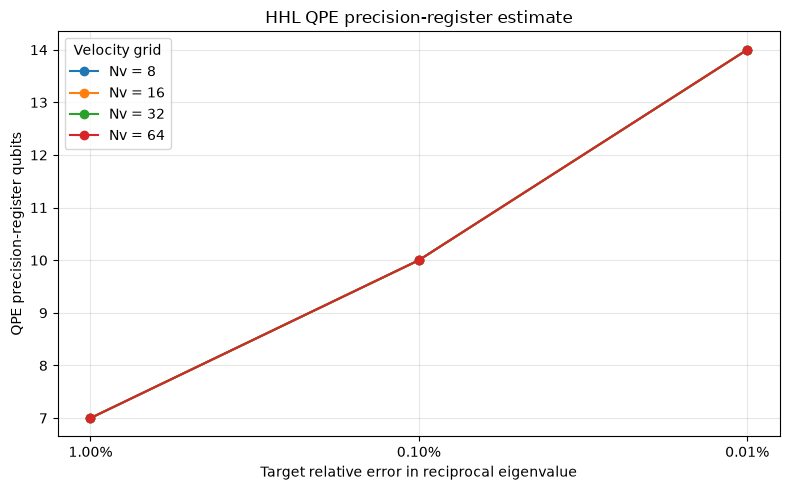

CSV saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\diagnostics\07_HHL_QPE_precision_estimates.csv
PNG saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\diagnostics\07_HHL_QPE_precision_estimates.png
PDF saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\diagnostics\07_HHL_QPE_precision_estimates.pdf


In [6]:

# Cell 4 — HHL phase-estimation precision and register-size estimates

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reconstruct paths explicitly; do not depend on an undefined results_dir.
project_root = Path(
    r"C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson"
)
results_dir = project_root / "results"
diagnostics_dir = results_dir / "diagnostics"
diagnostics_dir.mkdir(parents=True, exist_ok=True)

# Confirm that the expected HHL data are available.
required_columns = [
    "Nv",
    "condition_A",
    "minimum_absolute_eigenvalue",
    "dilation_qubits",
]
missing_columns = [
    col for col in required_columns if col not in hhl_df.columns
]
if missing_columns:
    raise ValueError(f"Missing HHL columns: {missing_columns}")

if hhl_df[required_columns].isna().any().any():
    raise ValueError("HHL input data contain missing values.")

# Target relative errors in the reciprocal eigenvalue.
target_errors = [1e-2, 1e-3, 1e-4]

records = []

for _, row in hhl_df.sort_values("Nv").iterrows():
    Nv = int(row["Nv"])
    condition_number = float(row["condition_A"])
    lambda_min = float(row["minimum_absolute_eigenvalue"])
    dilation_qubits = int(row["dilation_qubits"])

    # For the Hermitian dilation, eigenvalues are ± singular values of A.
    lambda_max = condition_number * lambda_min

    for epsilon_inv in target_errors:
        # Conservative eigenvalue-error bound ensuring reciprocal
        # relative error does not exceed epsilon_inv.
        delta_lambda_max = (
            epsilon_inv * lambda_min / (1.0 + epsilon_inv)
        )

        # Conservative QPE phase-resolution proxy:
        # delta_lambda <= lambda_max / 2**m.
        qpe_precision_qubits = int(
            np.ceil(np.log2(lambda_max / delta_lambda_max))
        )

        achieved_resolution_bound = (
            lambda_max / (2 ** qpe_precision_qubits)
        )

        records.append({
            "Nv": Nv,
            "condition_A": condition_number,
            "lambda_min_abs": lambda_min,
            "lambda_max_abs_estimate": lambda_max,
            "target_inverse_relative_error": epsilon_inv,
            "maximum_allowed_eigenvalue_error": delta_lambda_max,
            "QPE_precision_qubits": qpe_precision_qubits,
            "QPE_resolution_bound": achieved_resolution_bound,
            "dilation_system_qubits": dilation_qubits,
            "system_plus_QPE_register_qubits": (
                dilation_qubits + qpe_precision_qubits
            ),
        })

hhl_precision_df = pd.DataFrame(records)

# Save the numerical results.
csv_path = diagnostics_dir / "07_HHL_QPE_precision_estimates.csv"
hhl_precision_df.to_csv(csv_path, index=False)

# Display a compact table.
display_columns = [
    "Nv",
    "target_inverse_relative_error",
    "QPE_precision_qubits",
    "dilation_system_qubits",
    "system_plus_QPE_register_qubits",
]
display(
    hhl_precision_df[display_columns].sort_values(
        ["Nv", "target_inverse_relative_error"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

# Plot precision-register requirements.
pivot_df = hhl_precision_df.pivot(
    index="target_inverse_relative_error",
    columns="Nv",
    values="QPE_precision_qubits"
).sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))

for Nv in pivot_df.columns:
    ax.plot(
        [f"{x:.2%}" for x in pivot_df.index],
        pivot_df[Nv],
        marker="o",
        label=f"Nv = {Nv}"
    )

ax.set_xlabel("Target relative error in reciprocal eigenvalue")
ax.set_ylabel("QPE precision-register qubits")
ax.set_title("HHL QPE precision-register estimate")
ax.grid(True, alpha=0.3)
ax.legend(title="Velocity grid")
fig.tight_layout()

png_path = diagnostics_dir / "07_HHL_QPE_precision_estimates.png"
pdf_path = diagnostics_dir / "07_HHL_QPE_precision_estimates.pdf"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
plt.show()

print(f"CSV saved: {csv_path}")
print(f"PNG saved: {png_path}")
print(f"PDF saved: {pdf_path}")


,Nv,alpha_LCU,alpha_over_norm_A,matrix_reconstruction_error,block_encoding_error,unitarity_error_Frobenius,system_qubits,total_register_qubits,full_unitary_dimension,dense_unitary_storage_MiB,unitary_dimension_per_velocity_point,dense_storage_per_velocity_point_squared
0,8,1.00596428,1.00447316,2.16840434e-19,1.34943717e-16,6.91595587e-15,3,6,64,0.0625,8.0,0.00097656
1,16,1.00555826,1.00427154,4.33680869e-19,1.44349054e-16,1.47188216e-14,4,7,128,0.2500,8.0,0.00097656
2,32,1.00558091,1.00428276,4.33680869e-19,4.62152624e-17,1.68813831e-14,5,8,256,1.0000,8.0,0.00097656
3,64,1.00559163,1.00428808,4.33680869e-19,8.21988716e-18,4.82695697e-14,6,9,512,4.0000,8.0,0.00097656


,smallest_Nv,largest_Nv,Nv_growth_factor,alpha_LCU_smallest,alpha_LCU_largest,alpha_over_norm_A_smallest,alpha_over_norm_A_largest,system_qubits_smallest,system_qubits_largest,total_register_qubits_smallest,total_register_qubits_largest,unitary_dimension_smallest,unitary_dimension_largest,dense_storage_smallest_MiB,dense_storage_largest_MiB,empirical_dense_storage_exponent,maximum_reconstruction_error,maximum_block_encoding_error,maximum_unitarity_error
0,8,64,8.0,1.00596428,1.00559163,1.00447316,1.00428808,3,6,6,9,64,512,0.0625,4.0,2.0,4.33680869e-19,1.44349054e-16,4.82695697e-14


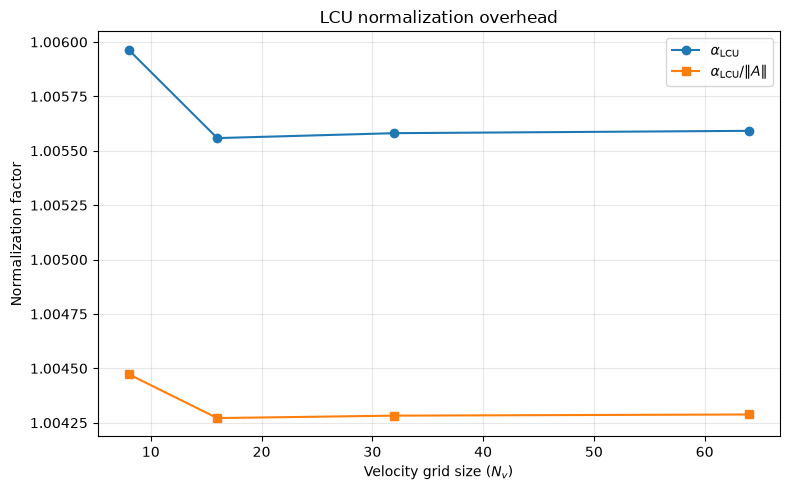

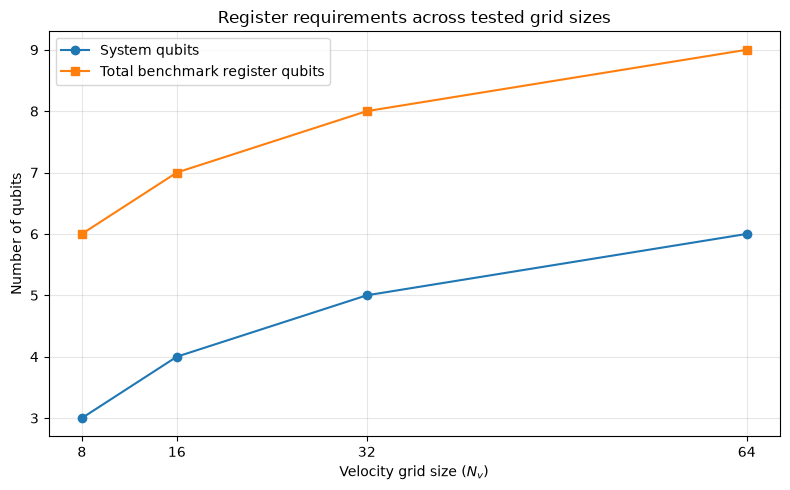

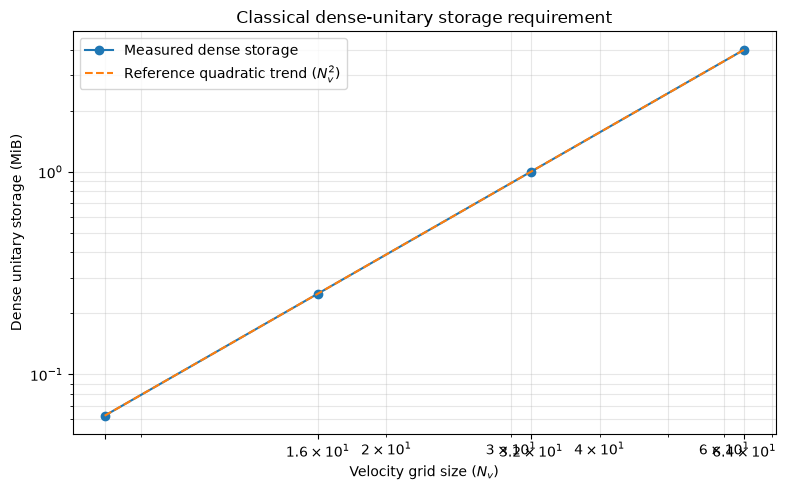

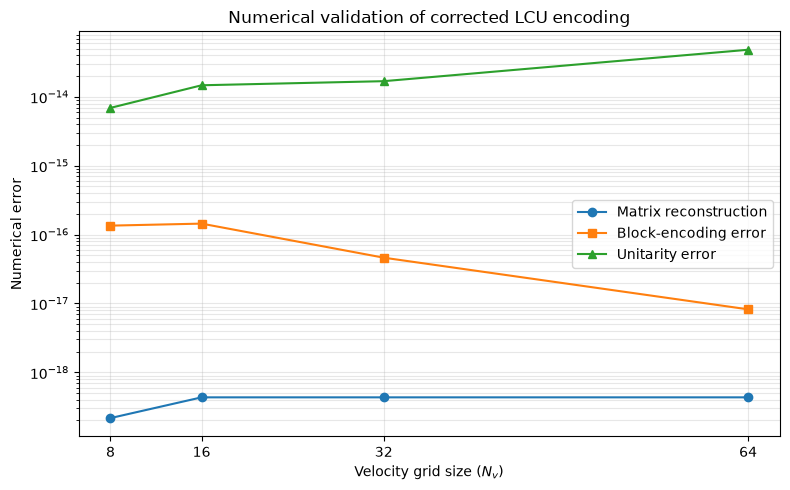


LCU scaling analysis completed.
Tables saved to: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables
Figures saved to: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures

Empirical dense-storage exponent:
2.0000

Maximum numerical errors:
Matrix reconstruction: 4.337e-19
Block encoding:        1.443e-16
Unitarity:             4.827e-14


In [7]:

# Cell 5 — Corrected LCU and block-encoding resource scaling

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Explicit project paths
# ---------------------------------------------------------

project_root = Path(
    r"C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson"
)

results_dir = project_root / "results"
tables_dir = results_dir / "tables"
figures_dir = results_dir / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# 2. Validate the corrected benchmark data
# ---------------------------------------------------------

required_columns = [
    "Nv",
    "alpha_LCU",
    "alpha_over_norm_A",
    "matrix_reconstruction_error",
    "block_encoding_error",
    "unitarity_error_Frobenius",
    "system_qubits",
    "total_register_qubits",
    "full_unitary_dimension",
    "dense_unitary_storage_MiB",
]

missing_columns = [
    col for col in required_columns if col not in matrix_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in corrected matrix benchmark: {missing_columns}"
    )

lcu_df = (
    matrix_df[required_columns]
    .copy()
    .sort_values("Nv")
    .reset_index(drop=True)
)

if lcu_df.isna().any().any():
    raise ValueError("The corrected LCU benchmark contains missing values.")

numeric_values = lcu_df.select_dtypes(include=[np.number]).to_numpy()

if not np.isfinite(numeric_values).all():
    raise ValueError("Non-finite numerical values detected.")

if len(lcu_df) < 2:
    raise ValueError("At least two grid sizes are required for scaling analysis.")

# ---------------------------------------------------------
# 3. Derived resource and scaling quantities
# ---------------------------------------------------------

lcu_df["unitary_dimension_per_velocity_point"] = (
    lcu_df["full_unitary_dimension"] / lcu_df["Nv"]
)

lcu_df["dense_storage_per_velocity_point_squared"] = (
    lcu_df["dense_unitary_storage_MiB"] / (lcu_df["Nv"] ** 2)
)

# Empirical finite-size exponent for dense-unitary storage.
# This is descriptive, not an asymptotic complexity proof.

storage_exponent = np.polyfit(
    np.log(lcu_df["Nv"]),
    np.log(lcu_df["dense_unitary_storage_MiB"]),
    1
)[0]

# Relative changes between the smallest and largest tested grids.

first = lcu_df.iloc[0]
last = lcu_df.iloc[-1]

scaling_summary = pd.DataFrame([{
    "smallest_Nv": int(first["Nv"]),
    "largest_Nv": int(last["Nv"]),
    "Nv_growth_factor": float(last["Nv"] / first["Nv"]),
    "alpha_LCU_smallest": float(first["alpha_LCU"]),
    "alpha_LCU_largest": float(last["alpha_LCU"]),
    "alpha_over_norm_A_smallest": float(first["alpha_over_norm_A"]),
    "alpha_over_norm_A_largest": float(last["alpha_over_norm_A"]),
    "system_qubits_smallest": int(first["system_qubits"]),
    "system_qubits_largest": int(last["system_qubits"]),
    "total_register_qubits_smallest": int(first["total_register_qubits"]),
    "total_register_qubits_largest": int(last["total_register_qubits"]),
    "unitary_dimension_smallest": int(first["full_unitary_dimension"]),
    "unitary_dimension_largest": int(last["full_unitary_dimension"]),
    "dense_storage_smallest_MiB": float(first["dense_unitary_storage_MiB"]),
    "dense_storage_largest_MiB": float(last["dense_unitary_storage_MiB"]),
    "empirical_dense_storage_exponent": float(storage_exponent),
    "maximum_reconstruction_error": float(
        lcu_df["matrix_reconstruction_error"].max()
    ),
    "maximum_block_encoding_error": float(
        lcu_df["block_encoding_error"].max()
    ),
    "maximum_unitarity_error": float(
        lcu_df["unitarity_error_Frobenius"].max()
    ),
}])

# ---------------------------------------------------------
# 4. Save substantive numerical outputs
# ---------------------------------------------------------

scaling_csv = tables_dir / "LCU_resource_scaling.csv"
summary_csv = tables_dir / "LCU_resource_scaling_summary.csv"

lcu_df.to_csv(scaling_csv, index=False)
scaling_summary.to_csv(summary_csv, index=False)

display(lcu_df)
display(scaling_summary)

# ---------------------------------------------------------
# 5. Figure 1 — LCU normalization overhead
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    lcu_df["Nv"],
    lcu_df["alpha_LCU"],
    marker="o",
    label=r"$\alpha_{\mathrm{LCU}}$"
)

ax.plot(
    lcu_df["Nv"],
    lcu_df["alpha_over_norm_A"],
    marker="s",
    label=r"$\alpha_{\mathrm{LCU}}/\|A\|$"
)

ax.set_xlabel(r"Velocity grid size ($N_v$)")
ax.set_ylabel("Normalization factor")
ax.set_title("LCU normalization overhead")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "LCU_normalization_scaling.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figures_dir / "LCU_normalization_scaling.pdf",
    bbox_inches="tight"
)
plt.show()

# ---------------------------------------------------------
# 6. Figure 2 — Register and unitary-dimension scaling
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    lcu_df["Nv"],
    lcu_df["system_qubits"],
    marker="o",
    label="System qubits"
)

ax.plot(
    lcu_df["Nv"],
    lcu_df["total_register_qubits"],
    marker="s",
    label="Total benchmark register qubits"
)

ax.set_xlabel(r"Velocity grid size ($N_v$)")
ax.set_ylabel("Number of qubits")
ax.set_title("Register requirements across tested grid sizes")
ax.set_xticks(lcu_df["Nv"])
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "LCU_register_scaling.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figures_dir / "LCU_register_scaling.pdf",
    bbox_inches="tight"
)
plt.show()

# ---------------------------------------------------------
# 7. Figure 3 — Dense classical unitary storage
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(
    lcu_df["Nv"],
    lcu_df["dense_unitary_storage_MiB"],
    marker="o",
    label="Measured dense storage"
)

reference_storage = (
    lcu_df["dense_unitary_storage_MiB"].iloc[0]
    * (lcu_df["Nv"] / lcu_df["Nv"].iloc[0]) ** 2
)

ax.loglog(
    lcu_df["Nv"],
    reference_storage,
    linestyle="--",
    label=r"Reference quadratic trend ($N_v^2$)"
)

ax.set_xlabel(r"Velocity grid size ($N_v$)")
ax.set_ylabel("Dense unitary storage (MiB)")
ax.set_title("Classical dense-unitary storage requirement")
ax.set_xticks(lcu_df["Nv"])
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "LCU_dense_storage_scaling.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figures_dir / "LCU_dense_storage_scaling.pdf",
    bbox_inches="tight"
)
plt.show()

# ---------------------------------------------------------
# 8. Figure 4 — Numerical encoding accuracy
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.semilogy(
    lcu_df["Nv"],
    lcu_df["matrix_reconstruction_error"],
    marker="o",
    label="Matrix reconstruction"
)

ax.semilogy(
    lcu_df["Nv"],
    lcu_df["block_encoding_error"],
    marker="s",
    label="Block-encoding error"
)

ax.semilogy(
    lcu_df["Nv"],
    lcu_df["unitarity_error_Frobenius"],
    marker="^",
    label="Unitarity error"
)

ax.set_xlabel(r"Velocity grid size ($N_v$)")
ax.set_ylabel("Numerical error")
ax.set_title("Numerical validation of corrected LCU encoding")
ax.set_xticks(lcu_df["Nv"])
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "LCU_encoding_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figures_dir / "LCU_encoding_accuracy.pdf",
    bbox_inches="tight"
)
plt.show()

# ---------------------------------------------------------
# 9. Report saved outputs
# ---------------------------------------------------------

print("\nLCU scaling analysis completed.")
print(f"Tables saved to: {tables_dir}")
print(f"Figures saved to: {figures_dir}")

print("\nEmpirical dense-storage exponent:")
print(f"{storage_exponent:.4f}")

print("\nMaximum numerical errors:")
print(f"Matrix reconstruction: {lcu_df['matrix_reconstruction_error'].max():.3e}")
print(f"Block encoding:        {lcu_df['block_encoding_error'].max():.3e}")
print(f"Unitarity:             {lcu_df['unitarity_error_Frobenius'].max():.3e}")


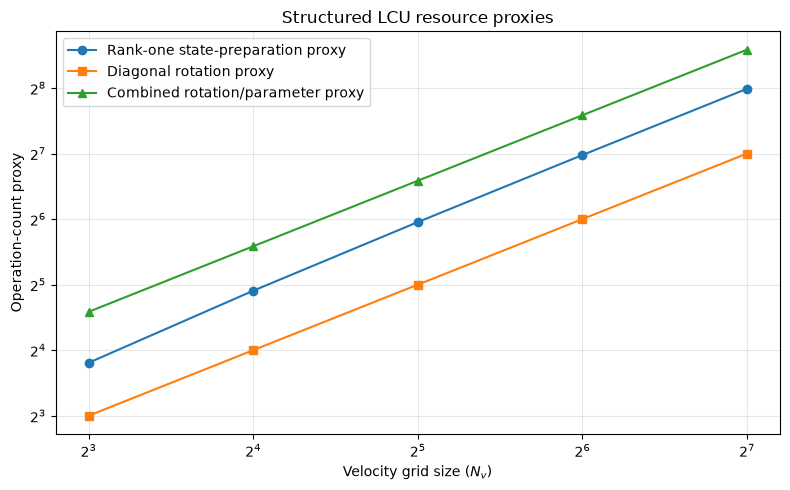

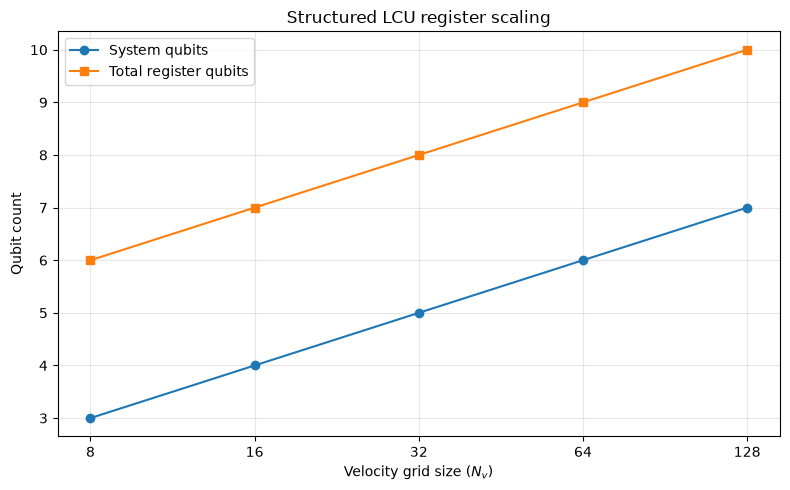

STRUCTURED LCU RESOURCE AUDIT

Grid-by-grid validation status:
 Nv  combined_rotation_parameter_proxy  total_register_qubits  resource_formula_checks_pass  structured_validation_pass                     validation_status
  8                                 24                      6                          True                        True Validated against corrected benchmark
 16                                 48                      7                          True                        True Validated against corrected benchmark
 32                                 96                      8                          True                        True Validated against corrected benchmark
 64                                192                      9                          True                        True Validated against corrected benchmark
128                                384                     10                          True                       False           Not independently

In [8]:

# ============================================================
# CELL 6 — STRUCTURED LCU RESOURCE AUDIT AND SCALING
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Explicit project paths
# ------------------------------------------------------------

project_root = Path(
    r"C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson"
)

results_dir = project_root / "results"
tables_dir = results_dir / "tables"
figures_dir = results_dir / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Load existing resource and validation data
# ------------------------------------------------------------

resource_path = tables_dir / "structured_resource_estimates.csv"
validation_path = tables_dir / "structured_encoding_validation.csv"
matrix_path = tables_dir / "corrected_quantum_matrix_benchmark.csv"

for path in [resource_path, validation_path, matrix_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required input file not found: {path}")

resource_df = pd.read_csv(resource_path)
validation_df = pd.read_csv(validation_path)
corrected_matrix_df = pd.read_csv(matrix_path)

# Required columns
resource_required = [
    "Nv",
    "system_qubits",
    "dilation_ancillas",
    "selector_qubits",
    "total_register_qubits",
    "rank_one_stateprep_rotation_proxy",
    "diagonal_rotation_proxy",
    "LCU_prepare_rotation_proxy",
    "combined_rotation_parameter_proxy",
    "dense_LCU_unitary_dimension",
    "dense_LCU_matrix_entries",
]

validation_required = [
    "Nv",
    "diagonal_unitarity_error_fro",
    "diagonal_block_error",
    "rank_one_factorization_error",
    "rank_R_numerical",
    "R_second_singular_value",
    "alpha",
]

matrix_required = ["Nv", "alpha_LCU"]

for name, df, required in [
    ("resource estimates", resource_df, resource_required),
    ("structured validation", validation_df, validation_required),
    ("corrected matrix benchmark", corrected_matrix_df, matrix_required),
]:
    missing = sorted(set(required) - set(df.columns))
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

# Ensure unique grid sizes
for name, df in [
    ("resource estimates", resource_df),
    ("structured validation", validation_df),
    ("corrected matrix benchmark", corrected_matrix_df),
]:
    if df["Nv"].duplicated().any():
        raise ValueError(f"Duplicate Nv values found in {name}.")

# ------------------------------------------------------------
# 3. Join the three datasets
# ------------------------------------------------------------

audit_df = resource_df.merge(
    validation_df,
    on="Nv",
    how="left",
    validate="one_to_one",
)

audit_df = audit_df.merge(
    corrected_matrix_df[["Nv", "alpha_LCU"]].rename(
        columns={"alpha_LCU": "corrected_matrix_alpha_LCU"}
    ),
    on="Nv",
    how="left",
    validate="one_to_one",
)

audit_df = audit_df.sort_values("Nv").reset_index(drop=True)

# ------------------------------------------------------------
# 4. Audit analytical resource-count relationships
# ------------------------------------------------------------

audit_df["expected_rank_one_proxy"] = 2 * audit_df["Nv"] - 2
audit_df["expected_diagonal_proxy"] = audit_df["Nv"]
audit_df["expected_LCU_prepare_proxy"] = 2

audit_df["expected_combined_proxy"] = (
    audit_df["expected_rank_one_proxy"]
    + audit_df["expected_diagonal_proxy"]
    + audit_df["expected_LCU_prepare_proxy"]
)

audit_df["expected_total_register_qubits"] = (
    audit_df["system_qubits"]
    + audit_df["dilation_ancillas"]
    + audit_df["selector_qubits"]
)

audit_df["expected_dense_unitary_dimension"] = (
    2 ** audit_df["total_register_qubits"]
)

audit_df["expected_dense_matrix_entries"] = (
    audit_df["expected_dense_unitary_dimension"] ** 2
)

audit_df["rank_one_proxy_match"] = np.isclose(
    audit_df["rank_one_stateprep_rotation_proxy"],
    audit_df["expected_rank_one_proxy"],
)

audit_df["diagonal_proxy_match"] = np.isclose(
    audit_df["diagonal_rotation_proxy"],
    audit_df["expected_diagonal_proxy"],
)

audit_df["LCU_prepare_proxy_match"] = np.isclose(
    audit_df["LCU_prepare_rotation_proxy"],
    audit_df["expected_LCU_prepare_proxy"],
)

audit_df["combined_proxy_match"] = np.isclose(
    audit_df["combined_rotation_parameter_proxy"],
    audit_df["expected_combined_proxy"],
)

audit_df["register_count_match"] = (
    audit_df["total_register_qubits"]
    == audit_df["expected_total_register_qubits"]
)

audit_df["dense_dimension_match"] = (
    audit_df["dense_LCU_unitary_dimension"]
    == audit_df["expected_dense_unitary_dimension"]
)

audit_df["dense_entries_match"] = (
    audit_df["dense_LCU_matrix_entries"]
    == audit_df["expected_dense_matrix_entries"]
)

# ------------------------------------------------------------
# 5. Validate against the corrected physical-sign benchmark
# ------------------------------------------------------------

audit_df["validation_available"] = (
    audit_df["rank_R_numerical"].notna()
    & audit_df["alpha"].notna()
    & audit_df["corrected_matrix_alpha_LCU"].notna()
)

audit_df["alpha_matches_corrected_matrix"] = np.isclose(
    audit_df["alpha"],
    audit_df["corrected_matrix_alpha_LCU"],
    rtol=1e-10,
    atol=1e-12,
    equal_nan=False,
)

validation_tolerance = 1e-12

audit_df["rank_one_structure_valid"] = (
    audit_df["rank_R_numerical"].eq(1)
    & (audit_df["rank_one_factorization_error"] <= validation_tolerance)
    & (audit_df["R_second_singular_value"] <= validation_tolerance)
)

audit_df["diagonal_encoding_valid"] = (
    (audit_df["diagonal_unitarity_error_fro"] <= validation_tolerance)
    & (audit_df["diagonal_block_error"] <= validation_tolerance)
)

audit_df["structured_validation_pass"] = (
    audit_df["validation_available"]
    & audit_df["alpha_matches_corrected_matrix"]
    & audit_df["rank_one_structure_valid"]
    & audit_df["diagonal_encoding_valid"]
)

audit_df["validation_status"] = np.where(
    audit_df["structured_validation_pass"],
    "Validated against corrected benchmark",
    np.where(
        audit_df["validation_available"],
        "Validation available but checks failed",
        "Not independently validated",
    ),
)

# ------------------------------------------------------------
# 6. Check all resource-count identities
# ------------------------------------------------------------

formula_columns = [
    "rank_one_proxy_match",
    "diagonal_proxy_match",
    "LCU_prepare_proxy_match",
    "combined_proxy_match",
    "register_count_match",
    "dense_dimension_match",
    "dense_entries_match",
]

audit_df["resource_formula_checks_pass"] = audit_df[
    formula_columns
].all(axis=1)

if not audit_df["resource_formula_checks_pass"].all():
    failed = audit_df.loc[
        ~audit_df["resource_formula_checks_pass"], "Nv"
    ].tolist()
    raise AssertionError(
        f"Resource formula checks failed for Nv={failed}"
    )

# ------------------------------------------------------------
# 7. Estimate empirical scaling exponents
# ------------------------------------------------------------

def loglog_exponent(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
        & (x > 0)
        & (y > 0)
    )

    if valid.sum() < 2:
        return np.nan

    return float(
        np.polyfit(np.log(x[valid]), np.log(y[valid]), 1)[0]
    )

scaling_summary = pd.DataFrame([{
    "number_of_grid_sizes": len(audit_df),
    "minimum_Nv": int(audit_df["Nv"].min()),
    "maximum_Nv": int(audit_df["Nv"].max()),
    "rank_one_proxy_exponent": loglog_exponent(
        audit_df["Nv"],
        audit_df["rank_one_stateprep_rotation_proxy"],
    ),
    "diagonal_proxy_exponent": loglog_exponent(
        audit_df["Nv"],
        audit_df["diagonal_rotation_proxy"],
    ),
    "combined_proxy_exponent": loglog_exponent(
        audit_df["Nv"],
        audit_df["combined_rotation_parameter_proxy"],
    ),
    "LCU_prepare_proxy_exponent": loglog_exponent(
        audit_df["Nv"],
        audit_df["LCU_prepare_rotation_proxy"],
    ),
    "maximum_validated_Nv": (
        int(audit_df.loc[
            audit_df["structured_validation_pass"], "Nv"
        ].max())
        if audit_df["structured_validation_pass"].any()
        else np.nan
    ),
    "validated_grid_sizes": int(
        audit_df["structured_validation_pass"].sum()
    ),
    "unvalidated_grid_sizes": int(
        (~audit_df["structured_validation_pass"]).sum()
    ),
    "all_resource_formula_checks_pass": bool(
        audit_df["resource_formula_checks_pass"].all()
    ),
}])

# ------------------------------------------------------------
# 8. Save substantive numerical outputs
# ------------------------------------------------------------

audit_csv = tables_dir / "structured_LCU_resource_audit.csv"
summary_csv = tables_dir / "structured_LCU_scaling_summary.csv"

audit_df.to_csv(audit_csv, index=False)
scaling_summary.to_csv(summary_csv, index=False)

# ------------------------------------------------------------
# 9. Figure 1 — Structured operation proxies
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    audit_df["Nv"],
    audit_df["rank_one_stateprep_rotation_proxy"],
    marker="o",
    label="Rank-one state-preparation proxy",
)

ax.plot(
    audit_df["Nv"],
    audit_df["diagonal_rotation_proxy"],
    marker="s",
    label="Diagonal rotation proxy",
)

ax.plot(
    audit_df["Nv"],
    audit_df["combined_rotation_parameter_proxy"],
    marker="^",
    label="Combined rotation/parameter proxy",
)

ax.set_xlabel("Velocity grid size ($N_v$)")
ax.set_ylabel("Operation-count proxy")
ax.set_title("Structured LCU resource proxies")
ax.set_xscale("log", base=2)
ax.set_yscale("log", base=2)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "structured_LCU_operation_proxies.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    figures_dir / "structured_LCU_operation_proxies.pdf",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. Figure 2 — Register scaling
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    audit_df["Nv"],
    audit_df["system_qubits"],
    marker="o",
    label="System qubits",
)

ax.plot(
    audit_df["Nv"],
    audit_df["total_register_qubits"],
    marker="s",
    label="Total register qubits",
)

ax.set_xlabel("Velocity grid size ($N_v$)")
ax.set_ylabel("Qubit count")
ax.set_title("Structured LCU register scaling")
ax.set_xscale("log", base=2)
ax.set_xticks(audit_df["Nv"])
ax.set_xticklabels(audit_df["Nv"].astype(str))
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "structured_LCU_register_scaling.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    figures_dir / "structured_LCU_register_scaling.pdf",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 11. Report
# ------------------------------------------------------------

print("STRUCTURED LCU RESOURCE AUDIT")
print("=" * 65)

print("\nGrid-by-grid validation status:")
print(
    audit_df[
        [
            "Nv",
            "combined_rotation_parameter_proxy",
            "total_register_qubits",
            "resource_formula_checks_pass",
            "structured_validation_pass",
            "validation_status",
        ]
    ].to_string(index=False)
)

print("\nScaling summary:")
print(scaling_summary.to_string(index=False))

print("\nSaved tables:")
print(audit_csv)
print(summary_csv)

print("\nSaved figures:")
print(figures_dir / "structured_LCU_operation_proxies.png")
print(figures_dir / "structured_LCU_operation_proxies.pdf")
print(figures_dir / "structured_LCU_register_scaling.png")
print(figures_dir / "structured_LCU_register_scaling.pdf")

print("\nCell 6 completed. No quantum simulations were rerun.")


In [1]:

# ============================================================
# CELL 7 — CONSTRUCTIVE RANK-ONE BLOCK-ENCODING VALIDATION
# Corrected electron Vlasov–Poisson sign convention
# Independent cell: reconstructs all inputs and paths.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Explicit project/output paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson"
)

RESULTS_DIR = PROJECT_ROOT / "results"
TABLE_DIR = RESULTS_DIR / "tables"
DIAGNOSTICS_DIR = RESULTS_DIR / "diagnostics"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. State-preparation unitary using a Householder reflection
# ------------------------------------------------------------

def householder_state_preparation(target):

    target = np.asarray(target, dtype=complex)
    target = target / np.linalg.norm(target)

    e0 = np.zeros_like(target)
    e0[0] = 1.0

    difference = e0 - target
    norm_difference = np.linalg.norm(difference)

    if norm_difference < 1e-14:
        return np.eye(len(target), dtype=complex)

    q = difference / norm_difference

    P = (
        np.eye(len(target), dtype=complex)
        - 2.0 * np.outer(q, q.conj())
    )

    # Validate state preparation.
    assert np.linalg.norm(
        P.conj().T @ P - np.eye(len(target)), 2
    ) < 1e-10

    assert np.linalg.norm(
        P[:, 0] - target, 2
    ) < 1e-10

    return P


# ------------------------------------------------------------
# 3. Reversible zero/nonzero predicate
#
# Q|x>|a> = |x>|a XOR (x != 0)>
#
# Register ordering: system register followed by flag ancilla.
# ------------------------------------------------------------

def zero_predicate_unitary(Nv):

    Q = np.zeros((2 * Nv, 2 * Nv), dtype=complex)

    for x in range(Nv):

        predicate = int(x != 0)

        for ancilla in (0, 1):

            input_index = 2 * x + ancilla

            output_ancilla = ancilla ^ predicate

            output_index = 2 * x + output_ancilla

            Q[output_index, input_index] = 1.0

    return Q


# ------------------------------------------------------------
# 4. Construct and validate the rank-one block encoding
# ------------------------------------------------------------

def validate_rank_one_encoding(
    Nv,
    k=0.5,
    dt=0.001,
    Vmax=6.0
):

    if Nv < 2 or (Nv & (Nv - 1)) != 0:
        raise ValueError(
            "Nv must be a power of two and at least 2."
        )

    # Velocity grid
    v = np.linspace(-Vmax, Vmax, Nv)

    dv = v[1] - v[0]

    # Trapezoidal integration weights
    w = np.full(Nv, dv, dtype=float)

    w[0] *= 0.5
    w[-1] *= 0.5

    # Maxwellian and derivative
    f0 = (
        np.exp(-v**2 / 2.0)
        / np.sqrt(2.0 * np.pi)
    )

    fp = -v * f0

    # Corrected physical rank-one term
    c = dt / (1j * k)

    R = c * np.outer(fp, w)

    beta_R = np.linalg.norm(R, 2)

    if beta_R <= 0:
        raise ValueError(
            "Rank-one term has zero norm."
        )

    # Factor normalized B_R
    u = fp / np.linalg.norm(fp)

    z = w / np.linalg.norm(w)

    phase = c / abs(c)

    B_R = R / beta_R

    B_factorized = (
        phase * np.outer(u, z)
    )

    factorization_error = np.linalg.norm(
        B_R - B_factorized, 2
    )

    # State preparation unitaries
    P_u = householder_state_preparation(u)

    P_z = householder_state_preparation(z)

    # Reversible predicate unitary
    Q = zero_predicate_unitary(Nv)

    I_flag = np.eye(2, dtype=complex)

    # Construct the proposed unitary
    U_base = (
        np.kron(P_u, I_flag)
        @ Q
        @ np.kron(P_z.conj().T, I_flag)
    )

    # Apply coefficient phase on the flag-zero output subspace
    phase_operator = np.eye(
        2 * Nv, dtype=complex
    )

    for x in range(Nv):

        phase_operator[2 * x, 2 * x] = phase

    U_R = phase_operator @ U_base

    # Extract flag-ancilla-zero block
    zero_flag_indices = np.arange(
        0, 2 * Nv, 2
    )

    encoded_block = U_R[
        np.ix_(
            zero_flag_indices,
            zero_flag_indices
        )
    ]

    # Validation errors
    block_error = np.linalg.norm(
        encoded_block - B_R, 2
    )

    unitarity_error = np.linalg.norm(
        U_R.conj().T @ U_R
        - np.eye(2 * Nv), 2
    )

    predicate_unitarity_error = np.linalg.norm(
        Q.conj().T @ Q
        - np.eye(2 * Nv), 2
    )

    return {

        "Nv": Nv,

        "system_qubits": int(np.log2(Nv)),

        "flag_ancillas": 1,

        "rank_R": int(np.linalg.matrix_rank(R)),

        "beta_R": beta_R,

        "factorization_error_2norm":
            factorization_error,

        "block_encoding_error_2norm":
            block_error,

        "unitarity_error_2norm":
            unitarity_error,

        "predicate_unitarity_error_2norm":
            predicate_unitarity_error,

        "full_unitary_dimension":
            2 * Nv,

        "block_encoding_pass":
            bool(block_error < 1e-10),

        "unitarity_pass":
            bool(unitarity_error < 1e-10),

        "factorization_pass":
            bool(factorization_error < 1e-10)
    }


# ------------------------------------------------------------
# 5. Run validation
# ------------------------------------------------------------

rank_one_validation_df = pd.DataFrame([

    validate_rank_one_encoding(
        Nv,
        k=0.5,
        dt=0.001,
        Vmax=6.0
    )

    for Nv in [8, 16, 32, 64]
])

display(rank_one_validation_df)


# ------------------------------------------------------------
# 6. Save numerical results
# ------------------------------------------------------------

csv_path = (
    TABLE_DIR
    / "rank_one_constructive_block_encoding_validation.csv"
)

rank_one_validation_df.to_csv(
    csv_path,
    index=False
)


# ------------------------------------------------------------
# 7. Save diagnostic report
# ------------------------------------------------------------

report_path = (
    DIAGNOSTICS_DIR
    / "rank_one_constructive_block_encoding_report.txt"
)

report_lines = [

    "CONSTRUCTIVE RANK-ONE BLOCK-ENCODING VALIDATION",

    "=" * 65,

    "Construction: state preparation + reversible zero/nonzero predicate",

    "Physical convention: corrected electron Vlasov-Poisson",

    f"Grid sizes tested: "
    f"{rank_one_validation_df['Nv'].tolist()}",

    "",

    "Maximum errors:",

    f"Factorization: "
    f"{rank_one_validation_df['factorization_error_2norm'].max():.6e}",

    f"Block encoding: "
    f"{rank_one_validation_df['block_encoding_error_2norm'].max():.6e}",

    f"Unitary: "
    f"{rank_one_validation_df['unitarity_error_2norm'].max():.6e}",

    f"Predicate unitary: "
    f"{rank_one_validation_df['predicate_unitarity_error_2norm'].max():.6e}",

    "",

    f"All factorization checks pass: "
    f"{rank_one_validation_df['factorization_pass'].all()}",

    f"All block-encoding checks pass: "
    f"{rank_one_validation_df['block_encoding_pass'].all()}",

    f"All unitarity checks pass: "
    f"{rank_one_validation_df['unitarity_pass'].all()}",

    "",

    "This is matrix-level numerical validation.",

    "It is not gate synthesis, gate-count estimation, circuit-depth",
    "measurement, or a hardware execution result."
]

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)


# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\nVALIDATION SUMMARY")
print("=" * 65)

print(f"CSV saved: {csv_path}")

print(f"Diagnostic report saved: {report_path}")

print(
    "All factorization checks pass:",
    rank_one_validation_df[
        "factorization_pass"
    ].all()
)

print(
    "All block-encoding checks pass:",
    rank_one_validation_df[
        "block_encoding_pass"
    ].all()
)

print(
    "All unitarity checks pass:",
    rank_one_validation_df[
        "unitarity_pass"
    ].all()
)


,Nv,system_qubits,flag_ancillas,rank_R,beta_R,factorization_error_2norm,block_encoding_error_2norm,unitarity_error_2norm,predicate_unitarity_error_2norm,full_unitary_dimension,block_encoding_pass,unitarity_pass,factorization_pass
0,8,3,1,1,0.002964,2.501873e-17,3.200695e-16,5.808186e-16,0.0,16,True,True,True
1,16,4,1,1,0.002558,2.254716e-16,4.254236e-16,5.700704e-16,0.0,32,True,True,True
2,32,5,1,1,0.002581,2.596179e-16,6.122461e-16,1.318563e-15,0.0,64,True,True,True
3,64,6,1,1,0.002592,5.208681e-16,5.564194e-16,3.010857e-15,0.0,128,True,True,True



VALIDATION SUMMARY
CSV saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\rank_one_constructive_block_encoding_validation.csv
Diagnostic report saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\diagnostics\rank_one_constructive_block_encoding_report.txt
All factorization checks pass: True
All block-encoding checks pass: True
All unitarity checks pass: True


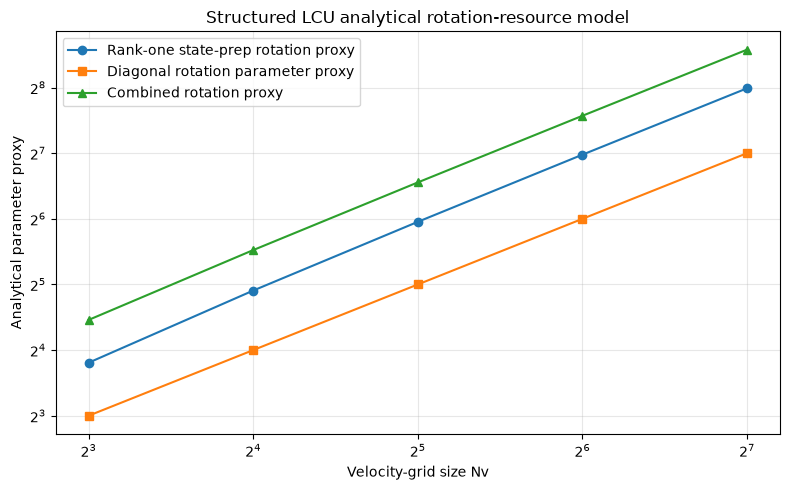

STRUCTURED LCU ANALYTICAL RESOURCE MODEL
 Nv  system_qubits  base_logical_qubits  predicate_work_ancillas  total_qubits_with_predicate_work  rank_one_state_prep_rotation_proxy  diagonal_rotation_parameter_proxy  combined_rotation_parameter_proxy  predicate_toffoli_estimate  predicate_cnot_equivalent_total  selector_prepare_cnot_upper_proxy
  8              3                    6                        1                                 7                                  14                                  8                                 22                           3                               18                                  6
 16              4                    7                        2                                 9                                  30                                 16                                 46                           5                               30                                  6
 32              5                    8                 

In [2]:
# ============================================================
# CELL 8 — TRANSPARENT STRUCTURED LCU RESOURCE MODEL
# Analytical resource proxies; no simulation or gate synthesis
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Explicit project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson"
)

RESULTS_DIR = PROJECT_ROOT / "results"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
DIAGNOSTICS_DIR = RESULTS_DIR / "diagnostics"

for directory in [TABLES_DIR, FIGURES_DIR, DIAGNOSTICS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Grid sizes from the existing structured-LCU benchmark
NV_GRID = [8, 16, 32, 64, 128]

# ------------------------------------------------------------
# 2. Resource-model assumptions
# ------------------------------------------------------------

# Generic real-amplitude state preparation:
# rotation-parameter proxy = Nv - 1 per prepared state
#
# Rank-one construction prepares two states (u and z).
# This is NOT a compiled gate count.

# Diagonal branch:
# one multiplexed rotation parameter per velocity-grid entry.
#
# This is NOT a synthesized CNOT count.

# Reversible predicate:
# Q|x>|flag> = |x>|flag XOR (x != 0)>
#
# For n >= 3, model a clean-ancilla AND chain to check x == 0,
# then invert the result to obtain x != 0.
#
# Toffoli estimate:
#   compute chain: n - 2 Toffolis
#   toggle flag:   1 Toffoli
#   uncompute:     n - 2 Toffolis
#
# Total = 2(n - 2) + 1
#
# For n = 2, use the identity:
# x1 OR x2 = x1 XOR x2 XOR (x1 AND x2)
#   -> 2 CNOT + 1 Toffoli
#
# For n = 1:
#   nonzero predicate = the single system bit
#   -> 1 CNOT

# Illustrative standard Toffoli decomposition:
# 6 CNOTs, excluding alternative native-gate implementations.
TOFFOLI_CNOT_EQUIVALENT = 6

# Generic upper bound for an arbitrary 2-qubit unitary:
# 3 CNOTs per unitary.
#
# PREPARE and PREPARE-dagger are both included.
GENERIC_2Q_UNITARY_CNOT_UPPER = 3

# ------------------------------------------------------------
# 3. Generate resource model
# ------------------------------------------------------------

rows = []

for Nv in NV_GRID:

    n_system = int(np.log2(Nv))
    assert 2**n_system == Nv, "Nv must be a power of 2."

    # Existing structured construction:
    dilation_ancillas = 1
    selector_qubits = 2

    # Base registers: system + dilation + selector
    base_logical_qubits = (
        n_system
        + dilation_ancillas
        + selector_qubits
    )

    # Predicate work-ancilla estimate
    predicate_work_ancillas = max(0, n_system - 2)

    total_qubits_with_predicate_work = (
        base_logical_qubits
        + predicate_work_ancillas
    )

    # --------------------------------------------------------
    # State preparation proxies
    # --------------------------------------------------------

    state_prep_u_rotation_proxy = Nv - 1
    state_prep_z_rotation_proxy = Nv - 1

    rank_one_state_prep_rotation_proxy = (
        state_prep_u_rotation_proxy
        + state_prep_z_rotation_proxy
    )

    # --------------------------------------------------------
    # Diagonal branch proxy
    # --------------------------------------------------------

    diagonal_rotation_parameter_proxy = Nv

    # --------------------------------------------------------
    # Reversible predicate estimate
    # --------------------------------------------------------

    if n_system == 1:

        predicate_toffoli_estimate = 0
        predicate_cnot_estimate = 1
        predicate_x_estimate = 0

    elif n_system == 2:

        # OR = x1 XOR x2 XOR (x1 AND x2)
        predicate_toffoli_estimate = 1
        predicate_cnot_estimate = 2
        predicate_x_estimate = 0

    else:

        predicate_toffoli_estimate = (
            2 * (n_system - 2) + 1
        )

        # Negative controls converted using X gates
        # before and after the zero-check.
        predicate_cnot_estimate = 0
        predicate_x_estimate = 2 * n_system + 1

    predicate_toffoli_cnot_equivalent = (
        predicate_toffoli_estimate
        * TOFFOLI_CNOT_EQUIVALENT
    )

    predicate_cnot_equivalent_total = (
        predicate_cnot_estimate
        + predicate_toffoli_cnot_equivalent
    )

    # --------------------------------------------------------
    # Selector preparation proxy
    # --------------------------------------------------------

    # Generic 2-qubit unitary upper-bound proxy:
    # PREPARE and PREPARE-dagger.
    selector_prepare_cnot_upper_proxy = (
        2 * GENERIC_2Q_UNITARY_CNOT_UPPER
    )

    # --------------------------------------------------------
    # Combined proxies (NOT actual gate counts)
    # --------------------------------------------------------

    combined_rotation_parameter_proxy = (
        rank_one_state_prep_rotation_proxy
        + diagonal_rotation_parameter_proxy
    )

    rows.append({

        "Nv": Nv,
        "system_qubits": n_system,
        "dilation_ancillas": dilation_ancillas,
        "selector_qubits": selector_qubits,
        "base_logical_qubits": base_logical_qubits,
        "predicate_work_ancillas": predicate_work_ancillas,
        "total_qubits_with_predicate_work":
            total_qubits_with_predicate_work,

        "state_prep_u_rotation_proxy":
            state_prep_u_rotation_proxy,
        "state_prep_z_rotation_proxy":
            state_prep_z_rotation_proxy,
        "rank_one_state_prep_rotation_proxy":
            rank_one_state_prep_rotation_proxy,

        "diagonal_rotation_parameter_proxy":
            diagonal_rotation_parameter_proxy,

        "combined_rotation_parameter_proxy":
            combined_rotation_parameter_proxy,

        "predicate_toffoli_estimate":
            predicate_toffoli_estimate,
        "predicate_direct_cnot_estimate":
            predicate_cnot_estimate,
        "predicate_toffoli_cnot_equivalent":
            predicate_toffoli_cnot_equivalent,
        "predicate_cnot_equivalent_total":
            predicate_cnot_equivalent_total,
        "predicate_x_gate_estimate":
            predicate_x_estimate,

        "selector_prepare_cnot_upper_proxy":
            selector_prepare_cnot_upper_proxy,

        "toffoli_cnot_assumption":
            TOFFOLI_CNOT_EQUIVALENT,

        "selector_generic_2q_cnot_assumption":
            GENERIC_2Q_UNITARY_CNOT_UPPER,

        "resource_model_status":
            "analytical_proxy_not_compiled"
    })

resource_model_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 4. Consistency checks
# ------------------------------------------------------------

assert (
    resource_model_df["base_logical_qubits"]
    ==
    resource_model_df["system_qubits"]
    + resource_model_df["dilation_ancillas"]
    + resource_model_df["selector_qubits"]
).all()

assert (
    resource_model_df["total_qubits_with_predicate_work"]
    ==
    resource_model_df["base_logical_qubits"]
    + resource_model_df["predicate_work_ancillas"]
).all()

assert (
    resource_model_df["rank_one_state_prep_rotation_proxy"]
    ==
    2 * (resource_model_df["Nv"] - 1)
).all()

assert (
    resource_model_df["combined_rotation_parameter_proxy"]
    ==
    3 * resource_model_df["Nv"] - 2
).all()

assert np.isfinite(
    resource_model_df.select_dtypes(include=np.number).to_numpy()
).all()

# ------------------------------------------------------------
# 5. Export table
# ------------------------------------------------------------

resource_model_csv = (
    TABLES_DIR
    / "structured_LCU_analytical_resource_model.csv"
)

resource_model_df.to_csv(
    resource_model_csv,
    index=False
)

# ------------------------------------------------------------
# 6. Export assumptions and interpretation report
# ------------------------------------------------------------

report_lines = [
    "STRUCTURED LCU ANALYTICAL RESOURCE MODEL",
    "=" * 65,
    "",
    "Purpose:",
    "Separate transparent analytical proxies from compiled circuit costs.",
    "",
    "Register assumptions:",
    "- System register: log2(Nv) qubits.",
    "- Block-encoding dilation: 1 ancilla qubit.",
    "- LCU selector: 2 qubits.",
    "- Predicate work ancillas: max(0, log2(Nv)-2) under the",
    "  clean-ancilla AND-chain model for Nv >= 8.",
    "",
    "State-preparation assumptions:",
    "- Generic real-amplitude state preparation proxy: Nv-1",
    "  rotation parameters per prepared state.",
    "- Rank-one branch prepares two states, u and z.",
    "- These rotation proxies are not compiled CNOT counts.",
    "",
    "Diagonal-branch assumption:",
    "- Nv multiplexed rotation parameters.",
    "- No CNOT count or depth is claimed.",
    "",
    "Predicate model:",
    "- Reversible predicate Q computes x != 0.",
    "- For n >= 3 system qubits, Toffoli estimate is",
    "  2(n-2)+1 under the stated clean-ancilla chain.",
    "- For n=2, use 2 CNOT + 1 Toffoli.",
    "- For n=1, use 1 CNOT.",
    "",
    "Gate-conversion assumptions:",
    f"- Toffoli illustrative conversion: {TOFFOLI_CNOT_EQUIVALENT} CNOT.",
    f"- Generic 2-qubit unitary upper-bound proxy:",
    f"  {GENERIC_2Q_UNITARY_CNOT_UPPER} CNOT.",
    "- PREPARE and PREPARE-dagger are both included in the",
    "  selector preparation proxy.",
    "",
    "Excluded from this model:",
    "- Synthesis of state-preparation circuits.",
    "- Synthesis of multiplexed diagonal rotations.",
    "- SELECT control synthesis.",
    "- Controlled dilation operations.",
    "- Precision-dependent gate synthesis.",
    "- Error-correction overhead.",
    "- Noise, hardware routing, SWAP overhead.",
    "- Circuit depth and parallel scheduling.",
    "",
    "Interpretation:",
    "- Rotation proxies are analytical counts of parameterized",
    "  rotations under generic constructions.",
    "- Predicate Toffoli estimates depend on the stated",
    "  reversible implementation.",
    "- CNOT-equivalent estimates are illustrative conversions,",
    "  not gate-synthesized benchmark results.",
    "- No hardware or compiled-circuit performance is claimed.",
    "",
    "END OF REPORT"
]

resource_model_report = "\n".join(report_lines)

report_path = (
    DIAGNOSTICS_DIR
    / "structured_LCU_analytical_resource_model_report.txt"
)

report_path.write_text(
    resource_model_report,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 7. Visualize resource proxies
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    resource_model_df["Nv"],
    resource_model_df["rank_one_state_prep_rotation_proxy"],
    marker="o",
    label="Rank-one state-prep rotation proxy"
)

ax.plot(
    resource_model_df["Nv"],
    resource_model_df["diagonal_rotation_parameter_proxy"],
    marker="s",
    label="Diagonal rotation parameter proxy"
)

ax.plot(
    resource_model_df["Nv"],
    resource_model_df["combined_rotation_parameter_proxy"],
    marker="^",
    label="Combined rotation proxy"
)

ax.set_xlabel("Velocity-grid size Nv")
ax.set_ylabel("Analytical parameter proxy")
ax.set_title("Structured LCU analytical rotation-resource model")
ax.set_xscale("log", base=2)
ax.set_yscale("log", base=2)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()

figure_png = (
    FIGURES_DIR
    / "structured_LCU_analytical_rotation_resource_model.png"
)

figure_pdf = (
    FIGURES_DIR
    / "structured_LCU_analytical_rotation_resource_model.pdf"
)

fig.savefig(figure_png, dpi=300, bbox_inches="tight")
fig.savefig(figure_pdf, bbox_inches="tight")

plt.show()

# ------------------------------------------------------------
# 8. Display results
# ------------------------------------------------------------

print("=" * 75)
print("STRUCTURED LCU ANALYTICAL RESOURCE MODEL")
print("=" * 75)

display_columns = [
    "Nv",
    "system_qubits",
    "base_logical_qubits",
    "predicate_work_ancillas",
    "total_qubits_with_predicate_work",
    "rank_one_state_prep_rotation_proxy",
    "diagonal_rotation_parameter_proxy",
    "combined_rotation_parameter_proxy",
    "predicate_toffoli_estimate",
    "predicate_cnot_equivalent_total",
    "selector_prepare_cnot_upper_proxy",
]

print(
    resource_model_df[display_columns]
    .to_string(index=False)
)

print("\nAll analytical consistency checks passed.")

print("\nSaved:")
print(resource_model_csv)
print(report_path)
print(figure_png)
print(figure_pdf)

print("\nImportant:")
print("These are analytical resource proxies.")
print("No circuit compilation, gate synthesis, or hardware execution occurred.")

In [3]:
# ============================================================
# CELL 9 — UNIFIED HHL / VQLS / STRUCTURED LCU COMPARISON
# Reads saved results only; no simulations are rerun.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Explicit paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson"
)

TABLES_DIR = PROJECT_ROOT / "results" / "tables"
DIAGNOSTICS_DIR = PROJECT_ROOT / "results" / "diagnostics"

DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

direct_path = TABLES_DIR / "HHL_VQLS_direct_comparison.csv"
resource_path = TABLES_DIR / "structured_LCU_analytical_resource_model.csv"
rank1_validation_path = (
    TABLES_DIR
    / "rank_one_constructive_block_encoding_validation.csv"
)

for path in [direct_path, resource_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required file missing: {path}")

direct_df = pd.read_csv(direct_path)
resource_df = pd.read_csv(resource_path)

# Optional validation dataset
rank1_validation_df = (
    pd.read_csv(rank1_validation_path)
    if rank1_validation_path.exists()
    else None
)

# ------------------------------------------------------------
# 2. Select the common benchmark grid
# ------------------------------------------------------------

TARGET_NV = 32

direct_32 = direct_df[
    direct_df["Nv"] == TARGET_NV
].copy()

resource_32 = resource_df[
    resource_df["Nv"] == TARGET_NV
].copy()

assert len(direct_32) == 2
assert len(resource_32) == 1

hhl_row = direct_32[
    direct_32["solver"] == "Ideal spectral HHL"
].iloc[0]

vqls_row = direct_32[
    direct_32["solver"] == "VQLS"
].iloc[0]

lcu_row = resource_32.iloc[0]

# ------------------------------------------------------------
# 3. Retrieve rank-one validation errors if available
# ------------------------------------------------------------

rank1_block_error = np.nan
rank1_unitarity_error = np.nan
rank1_factorization_error = np.nan

if rank1_validation_df is not None:

    rank1_32 = rank1_validation_df[
        rank1_validation_df["Nv"] == TARGET_NV
    ]

    if len(rank1_32) == 1:

        rank1_row = rank1_32.iloc[0]

        if "block_encoding_error_2norm" in rank1_row.index:
            rank1_block_error = float(
                rank1_row["block_encoding_error_2norm"]
            )

        if "unitarity_error_2norm" in rank1_row.index:
            rank1_unitarity_error = float(
                rank1_row["unitarity_error_2norm"]
            )

        if "factorization_error_2norm" in rank1_row.index:
            rank1_factorization_error = float(
                rank1_row["factorization_error_2norm"]
            )

# ------------------------------------------------------------
# 4. Construct unified comparison table
# ------------------------------------------------------------

comparison_rows = [

    {
        "method": "Ideal spectral HHL",
        "Nv": TARGET_NV,

        "system_qubits": hhl_row["system_register_qubits"],
        "additional_qubits": np.nan,
        "total_qubits_reported": hhl_row["system_register_qubits"],

        "solution_fidelity": max(
            0.0,
            min(1.0, float(hhl_row["solution_fidelity"]))
        ),

        "infidelity": max(
            0.0,
            1.0 - float(hhl_row["solution_fidelity"])
        ),

        "relative_orthogonal_residual":
            hhl_row["relative_orthogonal_residual"],

        "postselection_probability":
            hhl_row["postselection_probability"],

        "ansatz_layers": np.nan,
        "trainable_parameters": np.nan,
        "rotation_gates_reported": np.nan,
        "CNOT_gates_reported": np.nan,
        "optimizer_iterations": np.nan,

        "state_prep_rotation_proxy": np.nan,
        "diagonal_rotation_proxy": np.nan,
        "combined_rotation_proxy": np.nan,

        "predicate_toffoli_estimate": np.nan,
        "predicate_CNOT_equivalent_proxy": np.nan,
        "selector_PREPARE_CNOT_proxy": np.nan,

        "rank_one_block_encoding_error": np.nan,
        "rank_one_unitarity_error": np.nan,
        "rank_one_factorization_error": np.nan,

        "benchmark_status":
            "Ideal spectral simulation; not gate-synthesized"
    },

    {
        "method": "VQLS",
        "Nv": TARGET_NV,

        "system_qubits": vqls_row["system_register_qubits"],
        "additional_qubits": np.nan,
        "total_qubits_reported": vqls_row["system_register_qubits"],

        "solution_fidelity": float(
            vqls_row["solution_fidelity"]
        ),

        "infidelity": max(
            0.0,
            1.0 - float(vqls_row["solution_fidelity"])
        ),

        "relative_orthogonal_residual":
            vqls_row["relative_orthogonal_residual"],

        "postselection_probability": np.nan,

        "ansatz_layers": vqls_row["ansatz_layers"],
        "trainable_parameters": vqls_row["trainable_parameters"],
        "rotation_gates_reported": vqls_row["rotation_gates"],
        "CNOT_gates_reported": vqls_row["CNOT_gates"],
        "optimizer_iterations": vqls_row["optimizer_iterations"],

        "state_prep_rotation_proxy": np.nan,
        "diagonal_rotation_proxy": np.nan,
        "combined_rotation_proxy": np.nan,

        "predicate_toffoli_estimate": np.nan,
        "predicate_CNOT_equivalent_proxy": np.nan,
        "selector_PREPARE_CNOT_proxy": np.nan,

        "rank_one_block_encoding_error": np.nan,
        "rank_one_unitarity_error": np.nan,
        "rank_one_factorization_error": np.nan,

        "benchmark_status":
            "Variational benchmark; optimizer reached iteration limit"
    },

    {
        "method": "Structured LCU encoding",
        "Nv": TARGET_NV,

        "system_qubits": lcu_row["system_qubits"],
        "additional_qubits": (
            lcu_row["dilation_ancillas"]
            + lcu_row["selector_qubits"]
            + lcu_row["predicate_work_ancillas"]
        ),

        "total_qubits_reported":
            lcu_row["total_qubits_with_predicate_work"],

        "solution_fidelity": np.nan,
        "infidelity": np.nan,
        "relative_orthogonal_residual": np.nan,
        "postselection_probability": np.nan,

        "ansatz_layers": np.nan,
        "trainable_parameters": np.nan,
        "rotation_gates_reported": np.nan,
        "CNOT_gates_reported": np.nan,
        "optimizer_iterations": np.nan,

        "state_prep_rotation_proxy":
            lcu_row["rank_one_state_prep_rotation_proxy"],

        "diagonal_rotation_proxy":
            lcu_row["diagonal_rotation_parameter_proxy"],

        "combined_rotation_proxy":
            lcu_row["combined_rotation_parameter_proxy"],

        "predicate_toffoli_estimate":
            lcu_row["predicate_toffoli_estimate"],

        "predicate_CNOT_equivalent_proxy":
            lcu_row["predicate_cnot_equivalent_total"],

        "selector_PREPARE_CNOT_proxy":
            lcu_row["selector_prepare_cnot_upper_proxy"],

        "rank_one_block_encoding_error":
            rank1_block_error,

        "rank_one_unitarity_error":
            rank1_unitarity_error,

        "rank_one_factorization_error":
            rank1_factorization_error,

        "benchmark_status":
            "Block-encoding validation and analytical resource model; "
            "solver performance not yet benchmarked"
    }
]

comparison_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 5. Structural checks
# ------------------------------------------------------------

assert comparison_df["method"].nunique() == 3
assert comparison_df["Nv"].eq(TARGET_NV).all()

lcu_check = comparison_df[
    comparison_df["method"] == "Structured LCU encoding"
].iloc[0]

assert (
    lcu_check["combined_rotation_proxy"]
    ==
    3 * TARGET_NV - 2
)

assert (
    lcu_check["total_qubits_reported"]
    ==
    lcu_check["system_qubits"]
    + lcu_check["additional_qubits"]
)

assert np.isfinite(
    comparison_df[
        ["system_qubits", "total_qubits_reported"]
    ].to_numpy(dtype=float)
).all()

# ------------------------------------------------------------
# 6. Export table
# ------------------------------------------------------------

comparison_csv = (
    TABLES_DIR
    / "unified_HHL_VQLS_structured_LCU_comparison.csv"
)

comparison_df.to_csv(
    comparison_csv,
    index=False
)

# ------------------------------------------------------------
# 7. Export interpretation report
# ------------------------------------------------------------

report_lines = [
    "UNIFIED HHL / VQLS / STRUCTURED LCU COMPARISON",
    "=" * 70,
    "",
    f"Common velocity-grid size: Nv = {TARGET_NV}",
    "",
    "HHL:",
    "- Ideal spectral benchmark.",
    "- Fidelity and postselection are from the saved direct comparison.",
    "- No compiled QPE, controlled evolution, or gate count is available.",
    "",
    "VQLS:",
    "- Fidelity, residual, ansatz size, rotation count, CNOT count,",
    "  and optimizer iterations are taken from the saved direct benchmark.",
    "- Optimizer iteration limit must not be confused with convergence",
    "  to a globally optimal solution.",
    "",
    "Structured LCU:",
    "- Logical register estimate includes system, dilation, selector,",
    "  and clean predicate work ancillas under the chosen model.",
    "- Rotation proxies are not compiled gate counts.",
    "- Predicate CNOT-equivalent value is based on an illustrative",
    "  Toffoli conversion.",
    "- SELECT synthesis, state-preparation synthesis, multiplexed",
    "  rotation synthesis, routing, depth, and hardware noise remain",
    "  excluded.",
    "- Solution fidelity, solver residual, and algorithmic success",
    "  probability have not yet been benchmarked for LCU.",
    "",
    "The methods are not yet a fully apples-to-apples algorithmic",
    "comparison. This table consolidates available evidence and",
    "clearly marks missing measurements.",
    "",
    "END OF REPORT"
]

comparison_report_path = (
    DIAGNOSTICS_DIR
    / "unified_HHL_VQLS_structured_LCU_comparison_report.txt"
)

comparison_report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. Display
# ------------------------------------------------------------

print("=" * 90)
print("UNIFIED COMPARISON — Nv = 32")
print("=" * 90)

print(
    comparison_df[
        [
            "method",
            "system_qubits",
            "total_qubits_reported",
            "solution_fidelity",
            "postselection_probability",
            "trainable_parameters",
            "CNOT_gates_reported",
            "combined_rotation_proxy",
            "predicate_toffoli_estimate",
            "benchmark_status"
        ]
    ].to_string(index=False)
)

print("\nStructural checks passed.")

print("\nSaved:")
print(comparison_csv)
print(comparison_report_path)

UNIFIED COMPARISON — Nv = 32
                 method  system_qubits  total_qubits_reported  solution_fidelity  postselection_probability  trainable_parameters  CNOT_gates_reported  combined_rotation_proxy  predicate_toffoli_estimate                                                                                benchmark_status
     Ideal spectral HHL              6                      6           1.000000                   0.997427                   NaN                  NaN                      NaN                         NaN                                                 Ideal spectral simulation; not gate-synthesized
                   VQLS              5                      5           0.999997                        NaN                  40.0                 16.0                      NaN                         NaN                                        Variational benchmark; optimizer reached iteration limit
Structured LCU encoding              5                     11          

In [4]:
# ============================================================
# CELL 10: IDEAL STRUCTURED-LCU INVERSE BENCHMARK
# Nv=32 | Standalone cell | No prior experiments rerun
#
# IMPORTANT:
# This is ideal spectral inversion using the normalized
# Hermitian dilation of the corrected LCU-encoded matrix.
# It is NOT a compiled LCU/QSVT circuit or hardware run.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name.lower() == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

TABLE_DIR = PROJECT_ROOT / "results" / "tables"
DIAG_DIR = PROJECT_ROOT / "results" / "diagnostics"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
DIAG_DIR.mkdir(parents=True, exist_ok=True)

direct_path = TABLE_DIR / "HHL_VQLS_direct_comparison.csv"
vectors_path = TABLE_DIR / "HHL_VQLS_solution_vectors.csv"

for path in [direct_path, vectors_path]:
    if not path.exists():
        raise FileNotFoundError(
            f"Required saved file is missing:\n{path}"
        )

# ------------------------------------------------------------
# 2. Reconstruct the corrected Nv=32 reference system
# ------------------------------------------------------------

Nv = 32
k = 0.5
dt = 0.001
Vmax = 6.0

v = np.linspace(-Vmax, Vmax, Nv)
dv = v[1] - v[0]

w = np.full(Nv, dv, dtype=float)
w[0] *= 0.5
w[-1] *= 0.5

f0 = (
    np.exp(-v**2 / 2)
    / np.sqrt(2 * np.pi)
)

fp = -v * f0

I = np.eye(Nv, dtype=complex)
V = np.diag(v.astype(complex))

# Corrected physical operator:
# M = -ikV - (1/ik) fp w^T
M = (
    -1j * k * V
    - np.outer(fp, w) / (1j * k)
)

# Implicit Euler matrix
A = I - dt * M

# Independently reconstructed structured decomposition
D = 1j * dt * k * V
R = (dt / (1j * k)) * np.outer(fp, w)

A_structured = I + D + R

matrix_reconstruction_error = np.linalg.norm(
    A - A_structured, 2
)

# ------------------------------------------------------------
# 3. LCU normalization
# ------------------------------------------------------------

beta_I = np.linalg.norm(I, 2)
beta_D = np.linalg.norm(D, 2)
beta_R = np.linalg.norm(R, 2)

alpha_LCU = beta_I + beta_D + beta_R

# Normalized operator components
B_I = I / beta_I
B_D = D / beta_D
B_R = R / beta_R

# ------------------------------------------------------------
# 4. Normalized Hermitian dilation
# ------------------------------------------------------------

Z = np.zeros_like(A)

H = np.block([
    [Z, A],
    [A.conj().T, Z]
])

B_H = H / alpha_LCU

hermiticity_error = np.linalg.norm(
    H - H.conj().T, 2
)

# ------------------------------------------------------------
# 5. Ideal spectral inverse transformation
# ------------------------------------------------------------

eigvals, eigvecs = np.linalg.eigh(B_H)

min_abs_eigenvalue = float(
    np.min(np.abs(eigvals))
)

if min_abs_eigenvalue <= 1e-14:
    raise RuntimeError(
        "Normalized Hermitian dilation is singular "
        "or numerically ill-conditioned."
    )

# Maxwellian RHS |b>
b = f0.astype(complex)
b /= np.linalg.norm(b)

# Hermitian-dilation input state |b,0>
q = np.concatenate([
    b,
    np.zeros(Nv, dtype=complex)
])

q /= np.linalg.norm(q)

# Scaled ideal inverse:
# gamma * (B_H)^(-1)
#
# gamma = min |lambda(B_H)| ensures |gamma/lambda| <= 1
gamma = min_abs_eigenvalue

spectral_coefficients = (
    eigvecs.conj().T @ q
)

psi_un_normalized = (
    gamma
    * eigvecs
    @ (
        spectral_coefficients
        / eigvals
    )
)

# ------------------------------------------------------------
# 6. Inverse-transform success probability
# ------------------------------------------------------------

success_probability = float(
    np.vdot(
        psi_un_normalized,
        psi_un_normalized
    ).real
)

if (
    success_probability < -1e-10
    or success_probability > 1 + 1e-10
):
    raise RuntimeError(
        "Unphysical inverse-transform success probability: "
        f"{success_probability}"
    )

success_probability = float(
    np.clip(success_probability, 0.0, 1.0)
)

# Extract Hermitian-dilation blocks
upper_block = psi_un_normalized[:Nv]
lower_block = psi_un_normalized[Nv:]

upper_block_leakage = float(
    np.linalg.norm(upper_block)
)

lower_solution_probability = float(
    np.vdot(
        lower_block,
        lower_block
    ).real
)

if lower_solution_probability <= 0:
    raise RuntimeError(
        "Lower solution block has zero probability."
    )

# Conditional solution state
x_LCU = lower_block / np.linalg.norm(
    lower_block
)

# ------------------------------------------------------------
# 7. Classical reference solution
# ------------------------------------------------------------

x_classical = np.linalg.solve(A, b)
x_classical /= np.linalg.norm(x_classical)

# ------------------------------------------------------------
# 8. Common comparison metrics
# ------------------------------------------------------------

def solution_fidelity(reference, state):

    reference = reference / np.linalg.norm(reference)
    state = state / np.linalg.norm(state)

    return float(
        np.clip(
            np.abs(np.vdot(reference, state))**2,
            0.0,
            1.0
        )
    )


def relative_orthogonal_residual(
    A_mat,
    b_vec,
    state
):

    A_state = A_mat @ state

    projection = np.vdot(
        b_vec,
        A_state
    )

    residual = np.linalg.norm(
        A_state - projection * b_vec
    )

    denominator = np.linalg.norm(A_state)

    if denominator <= 0:
        return np.nan

    return float(
        residual / denominator
    )


def global_cost(
    A_mat,
    b_vec,
    state
):

    A_state = A_mat @ state

    denominator = np.vdot(
        A_state,
        A_state
    ).real

    if denominator <= 0:
        return np.nan

    numerator = np.abs(
        np.vdot(
            b_vec,
            A_state
        )
    )**2

    return float(
        np.clip(
            1.0 - numerator / denominator,
            0.0,
            1.0
        )
    )


# LCU metrics
lcu_fidelity = solution_fidelity(
    x_classical,
    x_LCU
)

lcu_residual = relative_orthogonal_residual(
    A,
    b,
    x_LCU
)

lcu_cost = global_cost(
    A,
    b,
    x_LCU
)

# ------------------------------------------------------------
# 9. Load existing HHL and VQLS data
# ------------------------------------------------------------

direct_df = pd.read_csv(
    direct_path
)

vectors_df = pd.read_csv(
    vectors_path
)

if len(vectors_df) != Nv:
    raise ValueError(
        f"Expected {Nv} saved solution-vector rows; "
        f"found {len(vectors_df)}."
    )


def complex_from_columns(
    df,
    real_column,
    imag_column
):

    return (
        df[real_column].to_numpy(dtype=float)
        + 1j
        * df[imag_column].to_numpy(dtype=float)
    )


x_HHL_saved = complex_from_columns(
    vectors_df,
    "HHL_real",
    "HHL_imag"
)

x_VQLS_saved = complex_from_columns(
    vectors_df,
    "VQLS_real",
    "VQLS_imag"
)

x_HHL_saved /= np.linalg.norm(
    x_HHL_saved
)

x_VQLS_saved /= np.linalg.norm(
    x_VQLS_saved
)

hhl_row = direct_df.loc[
    direct_df["solver"].str.contains(
        "HHL",
        case=False
    )
].iloc[0]

vqls_row = direct_df.loc[
    direct_df["solver"].str.contains(
        "VQLS",
        case=False
    )
].iloc[0]

# Recompute shared metrics from saved solution states.
hhl_fidelity = solution_fidelity(
    x_classical,
    x_HHL_saved
)

hhl_residual = relative_orthogonal_residual(
    A,
    b,
    x_HHL_saved
)

hhl_cost = global_cost(
    A,
    b,
    x_HHL_saved
)

vqls_fidelity = solution_fidelity(
    x_classical,
    x_VQLS_saved
)

vqls_residual = relative_orthogonal_residual(
    A,
    b,
    x_VQLS_saved
)

vqls_cost = global_cost(
    A,
    b,
    x_VQLS_saved
)

# ------------------------------------------------------------
# 10. Unified HHL / VQLS / LCU comparison
# ------------------------------------------------------------

comparison_rows = [

    {
        "method": "Ideal spectral HHL",
        "Nv": Nv,
        "solution_fidelity": hhl_fidelity,
        "global_cost": hhl_cost,
        "relative_orthogonal_residual": hhl_residual,
        "postselection_probability": float(
            hhl_row["postselection_probability"]
        ),
        "logical_qubits_reported": int(
            hhl_row["system_register_qubits"]
        ),
        "rotation_or_resource_proxy": np.nan,
        "CNOT_count_reported": np.nan,
        "benchmark_status":
            "Saved ideal spectral benchmark; "
            "not gate-synthesized"
    },

    {
        "method": "VQLS",
        "Nv": Nv,
        "solution_fidelity": vqls_fidelity,
        "global_cost": vqls_cost,
        "relative_orthogonal_residual": vqls_residual,
        "postselection_probability": np.nan,
        "logical_qubits_reported": int(
            vqls_row["system_register_qubits"]
        ),
        "rotation_or_resource_proxy": float(
            vqls_row["rotation_gates"]
        ),
        "CNOT_count_reported": float(
            vqls_row["CNOT_gates"]
        ),
        "benchmark_status":
            "Saved ideal variational statevector benchmark"
    },

    {
        "method":
            "Structured LCU ideal inverse transformation",
        "Nv": Nv,
        "solution_fidelity": lcu_fidelity,
        "global_cost": lcu_cost,
        "relative_orthogonal_residual": lcu_residual,
        "postselection_probability": success_probability,
        # Full inverse solver circuit resources
        # are NOT estimated.
        "logical_qubits_reported": np.nan,
        "rotation_or_resource_proxy": np.nan,
        "CNOT_count_reported": np.nan,
        "benchmark_status":
            "Ideal spectral inverse oracle; "
            "full solver circuit resources not estimated"
    }

]

comparison_df = pd.DataFrame(
    comparison_rows
)

# ------------------------------------------------------------
# 11. LCU-specific benchmark record
# ------------------------------------------------------------

lcu_benchmark_df = pd.DataFrame([{

    "Nv": Nv,
    "k": k,
    "dt": dt,

    "beta_I": beta_I,
    "beta_D": beta_D,
    "beta_R": beta_R,
    "alpha_LCU": alpha_LCU,

    "min_abs_eigenvalue_normalized_H":
        min_abs_eigenvalue,

    "inverse_transform_scale_gamma":
        gamma,

    "matrix_reconstruction_error_2norm":
        matrix_reconstruction_error,

    "hermiticity_error_2norm":
        hermiticity_error,

    "solution_fidelity":
        lcu_fidelity,

    "global_cost":
        lcu_cost,

    "relative_orthogonal_residual":
        lcu_residual,

    "inverse_transform_success_probability":
        success_probability,

    "upper_block_leakage_norm":
        upper_block_leakage,

    "lower_solution_block_probability":
        lower_solution_probability,

    # Do not assign the A-encoding qubit count to
    # the complete inverse solver.
    "full_solver_logical_qubits_estimate":
        np.nan,

    # Likewise, the 3Nv-2 proxy belongs to the
    # A-block-encoding construction, not the solver.
    "A_encoding_rotation_parameter_proxy":
        3 * Nv - 2,

    "A_encoding_predicate_toffoli_estimate":
        7,

    "A_encoding_predicate_CNOT_equivalent_proxy":
        42,

    "A_encoding_selector_PREPARE_CNOT_proxy":
        6,

    "status":
        "Ideal spectral inverse oracle; "
        "not compiled LCU/QSVT solver"

}])

# ------------------------------------------------------------
# 12. Save solution-vector comparison
# ------------------------------------------------------------

solution_df = pd.DataFrame({

    "velocity_index":
        np.arange(Nv),

    "velocity":
        v,

    "classical_real":
        x_classical.real,

    "classical_imag":
        x_classical.imag,

    "ideal_LCU_solution_real":
        x_LCU.real,

    "ideal_LCU_solution_imag":
        x_LCU.imag,

})


# ------------------------------------------------------------
# 13. Save CSV outputs
# ------------------------------------------------------------

lcu_benchmark_df.to_csv(
    TABLE_DIR
    / "ideal_structured_LCU_solver_benchmark.csv",
    index=False
)

comparison_df.to_csv(
    TABLE_DIR
    / "HHL_VQLS_ideal_LCU_solver_comparison.csv",
    index=False
)

solution_df.to_csv(
    TABLE_DIR
    / "ideal_structured_LCU_solution_vector.csv",
    index=False
)

# ------------------------------------------------------------
# 14. Generate diagnostic report
# ------------------------------------------------------------

report_lines = [

    "IDEAL STRUCTURED LCU INVERSE-TRANSFORM BENCHMARK",
    "=" * 72,

    f"Nv = {Nv}",
    f"k = {k}",
    f"dt = {dt}",

    "",
    "LCU normalization:",
    f"beta_I = {beta_I:.12e}",
    f"beta_D = {beta_D:.12e}",
    f"beta_R = {beta_R:.12e}",
    f"alpha_LCU = {alpha_LCU:.12e}",

    "",
    "Operator validation:",
    f"Matrix reconstruction error = "
    f"{matrix_reconstruction_error:.3e}",

    f"Hermiticity error = "
    f"{hermiticity_error:.3e}",

    "",
    "Ideal inverse benchmark:",
    f"Min |eigenvalue(B_H)| = "
    f"{min_abs_eigenvalue:.12e}",

    f"Inverse-transform scale gamma = "
    f"{gamma:.12e}",

    f"Solution fidelity = "
    f"{lcu_fidelity:.12f}",

    f"Global cost = "
    f"{lcu_cost:.12e}",

    f"Relative orthogonal residual = "
    f"{lcu_residual:.12e}",

    f"Inverse-transform success probability = "
    f"{success_probability:.12f}",

    f"Upper-block leakage norm = "
    f"{upper_block_leakage:.12e}",

    f"Lower solution-block probability = "
    f"{lower_solution_probability:.12f}",

    "",
    "Resource accounting:",
    "Full inverse solver qubit count: NOT ESTIMATED.",
    "Full inverse solver gate count: NOT ESTIMATED.",
    "Full inverse solver depth: NOT ESTIMATED.",

    "The 3Nv-2 rotation-parameter proxy, predicate estimates,",
    "and selector PREPARE proxy refer only to the previously",
    "analysed structured A block-encoding construction.",
    "They must not be interpreted as full solver resources.",

    "",
    "Excluded:",
    "Compiled SELECT operations, inverse/state preparation,",
    "controlled rotations, reciprocal synthesis, precision,",
    "routing, circuit depth, noise, error correction,",
    "and hardware execution.",

    "",
    "Interpretation:",
    "This experiment applies an ideal spectral reciprocal",
    "transformation to the normalized Hermitian dilation",
    "constructed from the structured LCU operator.",
    "It validates the ideal numerical inverse-solver path.",
    "It is not an implemented LCU or QSVT circuit.",

    "",
    "UNIFIED COMPARISON:",
    comparison_df.to_string(index=False),

    "",
    "END OF REPORT"
]

report_text = "\n".join(
    report_lines
)

report_path = (
    DIAG_DIR
    / "ideal_structured_LCU_solver_benchmark_report.txt"
)

report_path.write_text(
    report_text,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 15. Console summary and validation assertions
# ------------------------------------------------------------

assert matrix_reconstruction_error < 1e-10
assert hermiticity_error < 1e-10
assert upper_block_leakage < 1e-8
assert lcu_fidelity > 1 - 1e-8
assert lcu_residual < 1e-8
assert 0 <= success_probability <= 1 + 1e-10

print("=" * 72)
print("IDEAL STRUCTURED LCU INVERSE-TRANSFORM BENCHMARK")
print("=" * 72)

print(f"Nv:                         {Nv}")
print(f"LCU alpha:                  {alpha_LCU:.12f}")
print(f"Inverse scale gamma:        {gamma:.12e}")
print(f"Solution fidelity:          {lcu_fidelity:.12f}")
print(f"Global cost:                {lcu_cost:.3e}")
print(f"Relative orthogonal resid.:  {lcu_residual:.3e}")
print(f"Success probability:         {success_probability:.12f}")
print(f"Upper-block leakage:         {upper_block_leakage:.3e}")

print("\nUNIFIED COMPARISON")
print(comparison_df.to_string(index=False))

print("\nVALIDATION ASSERTIONS: PASSED")

print("\nSaved files:")
print(
    TABLE_DIR
    / "ideal_structured_LCU_solver_benchmark.csv"
)

print(
    TABLE_DIR
    / "HHL_VQLS_ideal_LCU_solver_comparison.csv"
)

print(
    TABLE_DIR
    / "ideal_structured_LCU_solution_vector.csv"
)

print(report_path)

IDEAL STRUCTURED LCU INVERSE-TRANSFORM BENCHMARK
Nv:                         32
LCU alpha:                  1.005580906240
Inverse scale gamma:        9.931689170023e-01
Solution fidelity:          1.000000000000
Global cost:                0.000e+00
Relative orthogonal resid.:  1.355e-15
Success probability:         0.997426929101
Upper-block leakage:         1.567e-15

UNIFIED COMPARISON
                                     method  Nv  solution_fidelity  global_cost  relative_orthogonal_residual  postselection_probability  logical_qubits_reported  rotation_or_resource_proxy  CNOT_count_reported                                                           benchmark_status
                         Ideal spectral HHL  32           1.000000 1.110223e-16                  1.330135e-15                   0.997427                      6.0                         NaN                  NaN                       Saved ideal spectral benchmark; not gate-synthesized
                                   

In [5]:

# ================================================================
# CELL 11 — VLASOV OPERATOR CONDITIONING AND SOURCE SENSITIVITY
# ================================================================
#
# Purpose:
# 1. Compare Maxwellian and symmetric two-beam equilibria.
# 2. Verify the dominant two-beam instability growth rate.
# 3. Measure how the implicit operator's condition number changes
#    as dt approaches the implicit-Euler singularity.
# 4. Measure sensitivity for the actual physical RHS state.
# 5. Compare worst-case matrix conditioning with RHS-specific
#    sensitivity and singular-vector overlap.
#
# IMPORTANT:
# This is a classical numerical conditioning audit.
# It is NOT a compiled HHL, VQLS, LCU, or QSVT circuit.
#
# Correct convention:
# M = -i*k*V - (1/(i*k))*outer(f0_prime, w)
# A = I - dt*M
#   = I + i*dt*k*V + dt/(i*k)*outer(f0_prime, w)
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. Locate the research project and output folders
# ------------------------------------------------

project_root = None

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "results").is_dir():
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project folder containing results/. "
        "Run this cell from the research project or notebooks folder."
    )

tables_dir = project_root / "results" / "tables"
figures_dir = project_root / "results" / "figures"
diagnostics_dir = project_root / "results" / "diagnostics"

for folder in [tables_dir, figures_dir, diagnostics_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 2. Physical and numerical parameters
# ------------------------------------------------

V_MAX = 6.0
K_WAVE = 0.5

GRID_SIZES = [32, 64, 128]

# Symmetric two-beam equilibrium:
# f0(v) = 0.5*N(v; +u, sigma^2)
#       + 0.5*N(v; -u, sigma^2)

BEAM_DRIFT = 2.0
BEAM_SIGMA = 0.5

# Time-step parameter is expressed relative to the
# inverse of the converged two-beam growth rate.
DT_GROWTH_FACTORS = np.array([
    0.02, 0.05, 0.10, 0.25, 0.50,
    0.75, 0.90, 0.95, 0.98, 1.02
])

SENSITIVITY_FACTORS = [0.10, 0.50, 0.90, 0.98]

RHS_PERTURBATIONS = [
    1e-10, 1e-8, 1e-6, 1e-4
]

DISTRIBUTIONS = ["Maxwellian", "Two-beam"]

RANDOM_SEED = 20261122

# ------------------------------------------------
# 3. Construct equilibrium distributions
# ------------------------------------------------

def construct_equilibrium(
    Nv,
    distribution,
    Vmax=V_MAX,
    drift=BEAM_DRIFT,
    sigma=BEAM_SIGMA
):
    """
    Returns:
        v  : uniform velocity grid
        w  : trapezoidal quadrature weights
        f0 : normalized equilibrium
        fp : analytic derivative of normalized equilibrium
    """

    v = np.linspace(-Vmax, Vmax, Nv)

    dv = v[1] - v[0]

    w = np.full(Nv, dv, dtype=float)
    w[0] *= 0.5
    w[-1] *= 0.5

    if distribution == "Maxwellian":

        raw = np.exp(-0.5 * v**2) / np.sqrt(2.0 * np.pi)

        draw = -v * raw

    elif distribution == "Two-beam":

        g_plus = np.exp(
            -0.5 * ((v - drift) / sigma)**2
        )

        g_minus = np.exp(
            -0.5 * ((v + drift) / sigma)**2
        )

        normalization = np.sqrt(2.0 * np.pi) * sigma

        raw = 0.5 * (g_plus + g_minus) / normalization

        draw = -0.5 * (
            ((v - drift) / sigma**2) * g_plus
            + ((v + drift) / sigma**2) * g_minus
        ) / normalization

    else:
        raise ValueError(f"Unknown distribution: {distribution}")

    # Normalize using the same quadrature used in the operator.
    density_integral = np.dot(w, raw)

    f0 = raw / density_integral
    fp = draw / density_integral

    if not np.isclose(np.dot(w, f0), 1.0, atol=1e-10):
        raise AssertionError("Equilibrium normalization failed.")

    return v, w, f0, fp


# ------------------------------------------------
# 4. Construct the corrected Vlasov operator
# ------------------------------------------------

def construct_operator(v, w, fp, k):
    """
    M = -i*k*V - (1/(i*k))*outer(fp,w)
    """

    Nv = len(v)

    V = np.diag(v.astype(np.complex128))

    M = (
        -1j * k * V
        - (1.0 / (1j * k)) * np.outer(fp, w)
    )

    return M


def construct_implicit_matrix(v, w, fp, k, dt):
    """
    A = I - dt*M
      = I + i*dt*k*V + dt/(i*k)*outer(fp,w)
    """

    Nv = len(v)

    I = np.eye(Nv, dtype=np.complex128)

    D = 1j * dt * k * np.diag(v)

    R = (dt / (1j * k)) * np.outer(fp, w)

    A = I + D + R

    return A, D, R


# ------------------------------------------------
# 5. Verify growth-rate convergence
# ------------------------------------------------

growth_rows = []
eigenvalue_cache = {}

for distribution in DISTRIBUTIONS:

    for Nv in GRID_SIZES:

        v, w, f0, fp = construct_equilibrium(
            Nv, distribution
        )

        M = construct_operator(
            v, w, fp, K_WAVE
        )

        eigenvalues = np.linalg.eigvals(M)

        idx = np.argmax(eigenvalues.real)

        dominant_eigenvalue = eigenvalues[idx]

        eigenvalue_cache[(distribution, Nv)] = dominant_eigenvalue

        growth_rows.append({
            "distribution": distribution,
            "Nv": Nv,
            "dominant_eigenvalue_real": float(
                dominant_eigenvalue.real
            ),
            "dominant_eigenvalue_imag": float(
                dominant_eigenvalue.imag
            ),
            "maximum_real_eigenvalue": float(
                np.max(eigenvalues.real)
            )
        })

growth_df = pd.DataFrame(growth_rows)

# Use the highest-resolution two-beam growth rate
# as the reference for the normalized time-step sweep.

two_beam_reference = growth_df[
    growth_df["distribution"] == "Two-beam"
].sort_values("Nv")

GAMMA_REFERENCE = float(
    two_beam_reference.iloc[-1]["dominant_eigenvalue_real"]
)

if GAMMA_REFERENCE <= 0:
    raise AssertionError(
        "The selected two-beam equilibrium did not produce "
        "a positive growth rate at the chosen resolution."
    )

growth_relative_error = (
    np.abs(
        two_beam_reference["dominant_eigenvalue_real"].to_numpy()
        - GAMMA_REFERENCE
    )
    / GAMMA_REFERENCE
)

if np.max(growth_relative_error) > 1e-3:
    raise AssertionError(
        "Two-beam growth-rate resolution convergence "
        "is insufficient. Increase velocity resolution."
    )

DT_POLE = 1.0 / GAMMA_REFERENCE

# ------------------------------------------------
# 6. Sweep operator conditioning
# ------------------------------------------------

condition_rows = []

for distribution in DISTRIBUTIONS:

    for Nv in GRID_SIZES:

        v, w, f0, fp = construct_equilibrium(
            Nv, distribution
        )

        M = construct_operator(
            v, w, fp, K_WAVE
        )

        dominant_eigenvalue = eigenvalue_cache[
            (distribution, Nv)
        ]

        # The initial Fourier perturbation is proportional
        # to the equilibrium distribution.
        b = f0.astype(np.complex128)
        b /= np.linalg.norm(b)

        for dt_factor in DT_GROWTH_FACTORS:

            dt = float(dt_factor / GAMMA_REFERENCE)

            A, D, R = construct_implicit_matrix(
                v, w, fp, K_WAVE, dt
            )

            # Independent reconstruction from A = I - dt*M.
            A_from_M = (
                np.eye(Nv, dtype=np.complex128)
                - dt * M
            )

            reconstruction_error = float(
                np.linalg.norm(A - A_from_M, ord=2)
            )

            # LCU normalization for I + D + R.
            beta_I = 1.0

            beta_D = float(
                dt * abs(K_WAVE) * np.max(np.abs(v))
            )

            beta_R = float(
                dt / abs(K_WAVE)
                * np.linalg.norm(fp)
                * np.linalg.norm(w)
            )

            alpha_LCU = beta_I + beta_D + beta_R

            # Singular-value decomposition.
            U, singular_values, Vh = np.linalg.svd(
                A, full_matrices=False
            )

            sigma_max = float(singular_values[0])
            sigma_min = float(singular_values[-1])

            if sigma_min <= 0:
                raise AssertionError(
                    "The implicit matrix is numerically singular."
                )

            condition_number = sigma_max / sigma_min

            inverse_norm = 1.0 / sigma_min

            # Hermitian dilation H/alpha has eigenvalues
            # plus/minus singular_values(A)/alpha.
            normalized_sigma_min = sigma_min / alpha_LCU
            normalized_sigma_max = sigma_max / alpha_LCU

            # Source-specific sensitivity:
            # ||A^-1|| * ||b|| / ||A^-1 b||
            x = np.linalg.solve(A, b)

            x_norm = np.linalg.norm(x)

            if x_norm == 0:
                raise AssertionError("Unexpected zero solution.")

            rhs_specific_sensitivity = (
                inverse_norm * np.linalg.norm(b) / x_norm
            )

            # Overlap of the source with the left singular vector
            # corresponding to the smallest singular value.
            smallest_left_vector = U[:, -1]

            source_smallest_left_overlap = float(
                abs(np.vdot(smallest_left_vector, b))
            )

            # Fraction of the normalized solution aligned with
            # the right singular vector associated with sigma_min.
            smallest_right_vector = Vh.conj().T[:, -1]

            solution_smallest_right_overlap = float(
                abs(
                    np.vdot(
                        smallest_right_vector,
                        x / x_norm
                    )
                )
            )

            # One-step implicit Euler modal amplification.
            lam = dominant_eigenvalue

            denominator = abs(1.0 - dt * lam)

            if denominator < 1e-14:
                euler_amplification = np.inf
            else:
                euler_amplification = 1.0 / denominator

            exact_modal_amplification = float(
                np.exp(dt * lam.real)
            )

            modal_amplification_relative_error = (
                abs(
                    euler_amplification
                    - exact_modal_amplification
                )
                / max(exact_modal_amplification, 1e-15)
            )

            condition_rows.append({
                "distribution": distribution,
                "Nv": Nv,
                "k": K_WAVE,
                "dt": dt,
                "dt_gamma_reference": float(dt_factor),
                "distance_from_reference_pole": float(
                    abs(1.0 - dt_factor)
                ),
                "dominant_growth_rate": float(lam.real),
                "dominant_eigenvalue_imag": float(lam.imag),
                "beta_I": beta_I,
                "beta_D": beta_D,
                "beta_R": beta_R,
                "alpha_LCU": alpha_LCU,
                "sigma_min_A": sigma_min,
                "sigma_max_A": sigma_max,
                "condition_number_A": condition_number,
                "inverse_operator_norm": inverse_norm,
                "normalized_sigma_min_H": normalized_sigma_min,
                "normalized_sigma_max_H": normalized_sigma_max,
                "condition_number_H": condition_number,
                "rhs_specific_sensitivity_factor": float(
                    rhs_specific_sensitivity
                ),
                "source_overlap_smallest_left_singular_vector":
                    source_smallest_left_overlap,
                "solution_overlap_smallest_right_singular_vector":
                    solution_smallest_right_overlap,
                "implicit_euler_modal_amplification": float(
                    euler_amplification
                ),
                "exact_modal_amplification": exact_modal_amplification,
                "modal_amplification_relative_error": float(
                    modal_amplification_relative_error
                ),
                "matrix_reconstruction_error": reconstruction_error,
                "encoding_spectral_bound_valid": bool(
                    normalized_sigma_max <= 1.0 + 1e-10
                )
            })

condition_df = pd.DataFrame(condition_rows)

# ------------------------------------------------
# 7. Controlled RHS perturbation sensitivity
# ------------------------------------------------

rng = np.random.default_rng(RANDOM_SEED)

sensitivity_rows = []

Nv = max(GRID_SIZES)

complex_noise = (
    rng.normal(size=Nv)
    + 1j * rng.normal(size=Nv)
)

complex_noise /= np.linalg.norm(complex_noise)

for distribution in DISTRIBUTIONS:

    v, w, f0, fp = construct_equilibrium(
        Nv, distribution
    )

    M = construct_operator(
        v, w, fp, K_WAVE
    )

    b = f0.astype(np.complex128)
    b /= np.linalg.norm(b)

    for dt_factor in SENSITIVITY_FACTORS:

        dt = float(dt_factor / GAMMA_REFERENCE)

        A, D, R = construct_implicit_matrix(
            v, w, fp, K_WAVE, dt
        )

        U, singular_values, Vh = np.linalg.svd(
            A, full_matrices=False
        )

        sigma_min = float(singular_values[-1])

        condition_number = float(
            singular_values[0] / sigma_min
        )

        x = np.linalg.solve(A, b)

        x_normalized = x / np.linalg.norm(x)

        source_condition_factor = (
            np.linalg.norm(b)
            / (sigma_min * np.linalg.norm(x))
        )

        for epsilon in RHS_PERTURBATIONS:

            b_perturbed = b + epsilon * complex_noise

            x_perturbed = np.linalg.solve(
                A, b_perturbed
            )

            x_perturbed_normalized = (
                x_perturbed / np.linalg.norm(x_perturbed)
            )

            relative_rhs_change = (
                np.linalg.norm(b_perturbed - b)
                / np.linalg.norm(b)
            )

            relative_solution_change = (
                np.linalg.norm(x_perturbed - x)
                / np.linalg.norm(x)
            )

            state_fidelity = float(
                abs(
                    np.vdot(
                        x_normalized,
                        x_perturbed_normalized
                    )
                )**2
            )

            perturbed_relative_residual = float(
                np.linalg.norm(
                    A @ x_perturbed - b_perturbed
                )
                / np.linalg.norm(b_perturbed)
            )

            sensitivity_rows.append({
                "distribution": distribution,
                "Nv": Nv,
                "dt": dt,
                "dt_gamma_reference": dt_factor,
                "rhs_perturbation_parameter": epsilon,
                "relative_rhs_change": float(relative_rhs_change),
                "condition_number_A": condition_number,
                "rhs_specific_sensitivity_factor": float(
                    source_condition_factor
                ),
                "relative_solution_change": float(
                    relative_solution_change
                ),
                "normalized_solution_state_fidelity": state_fidelity,
                "perturbed_relative_residual": perturbed_relative_residual
            })

sensitivity_df = pd.DataFrame(sensitivity_rows)

# ------------------------------------------------
# 8. Numerical validation
# ------------------------------------------------

if not np.isfinite(
    condition_df["condition_number_A"]
).all():
    raise AssertionError("Non-finite condition number detected.")

if not np.isfinite(
    sensitivity_df["normalized_solution_state_fidelity"]
).all():
    raise AssertionError("Non-finite sensitivity fidelity detected.")

if condition_df["matrix_reconstruction_error"].max() > 1e-10:
    raise AssertionError("Operator reconstruction check failed.")

if not condition_df["encoding_spectral_bound_valid"].all():
    raise AssertionError(
        "LCU normalization does not bound the encoded spectrum."
    )

if (
    sensitivity_df["normalized_solution_state_fidelity"].min()
    < -1e-12
    or sensitivity_df["normalized_solution_state_fidelity"].max()
    > 1.0 + 1e-10
):
    raise AssertionError("Invalid state fidelity encountered.")

# ------------------------------------------------
# 9. Save numerical tables
# ------------------------------------------------

growth_path = (
    tables_dir / "Vlasov_growth_rate_resolution.csv"
)

condition_path = (
    tables_dir / "Vlasov_operator_conditioning_sweep.csv"
)

sensitivity_path = (
    tables_dir / "Vlasov_rhs_sensitivity.csv"
)

growth_df.to_csv(growth_path, index=False)
condition_df.to_csv(condition_path, index=False)
sensitivity_df.to_csv(sensitivity_path, index=False)

# ------------------------------------------------
# 10. Plot condition number against dt*gamma
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for distribution in DISTRIBUTIONS:

    for Nv in GRID_SIZES:

        subset = condition_df[
            (condition_df["distribution"] == distribution)
            & (condition_df["Nv"] == Nv)
        ].sort_values("dt_gamma_reference")

        ax.plot(
            subset["dt_gamma_reference"],
            subset["condition_number_A"],
            marker="o",
            label=f"{distribution}, Nv={Nv}"
        )

ax.axvline(
    1.0,
    linestyle="--",
    linewidth=1.2,
    label="Reference implicit-Euler pole"
)

ax.set_yscale("log")
ax.set_xlabel(r"$\Delta t\,\gamma_{\mathrm{reference}}$")
ax.set_ylabel(r"$\kappa_2(A)$")
ax.set_title("Vlasov implicit-operator condition number")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "Vlasov_condition_number_vs_dt_growth_factor.png",
    dpi=300
)

fig.savefig(
    figures_dir / "Vlasov_condition_number_vs_dt_growth_factor.pdf"
)

plt.close(fig)

# ------------------------------------------------
# 11. Plot minimum singular value
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for distribution in DISTRIBUTIONS:

    for Nv in GRID_SIZES:

        subset = condition_df[
            (condition_df["distribution"] == distribution)
            & (condition_df["Nv"] == Nv)
        ].sort_values("dt_gamma_reference")

        ax.plot(
            subset["dt_gamma_reference"],
            subset["sigma_min_A"],
            marker="o",
            label=f"{distribution}, Nv={Nv}"
        )

ax.axvline(
    1.0,
    linestyle="--",
    linewidth=1.2,
    label="Reference implicit-Euler pole"
)

ax.set_yscale("log")
ax.set_xlabel(r"$\Delta t\,\gamma_{\mathrm{reference}}$")
ax.set_ylabel(r"$\sigma_{\min}(A)$")
ax.set_title("Smallest singular value of the implicit operator")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "Vlasov_min_singular_value_vs_dt_growth_factor.png",
    dpi=300
)

fig.savefig(
    figures_dir / "Vlasov_min_singular_value_vs_dt_growth_factor.pdf"
)

plt.close(fig)

# ------------------------------------------------
# 12. Plot RHS-specific sensitivity
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for distribution in DISTRIBUTIONS:

    subset = condition_df[
        (condition_df["distribution"] == distribution)
        & (condition_df["Nv"] == Nv)
    ].sort_values("dt_gamma_reference")

    ax.plot(
        subset["dt_gamma_reference"],
        subset["rhs_specific_sensitivity_factor"],
        marker="o",
        label=distribution
    )

ax.axvline(
    1.0,
    linestyle="--",
    linewidth=1.2,
    label="Reference implicit-Euler pole"
)

ax.set_yscale("log")
ax.set_xlabel(r"$\Delta t\,\gamma_{\mathrm{reference}}$")
ax.set_ylabel("RHS-specific inverse sensitivity factor")
ax.set_title("Source-dependent sensitivity of the inverse problem")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "Vlasov_rhs_sensitivity_vs_dt_growth_factor.png",
    dpi=300
)

fig.savefig(
    figures_dir / "Vlasov_rhs_sensitivity_vs_dt_growth_factor.pdf"
)

plt.close(fig)

# ------------------------------------------------
# 13. Write diagnostic report
# ------------------------------------------------

two_beam_N128 = growth_df[
    (growth_df["distribution"] == "Two-beam")
    & (growth_df["Nv"] == 128)
].iloc[0]

maxwellian_N128 = growth_df[
    (growth_df["distribution"] == "Maxwellian")
    & (growth_df["Nv"] == 128)
].iloc[0]

two_beam_condition = condition_df[
    (condition_df["distribution"] == "Two-beam")
    & (condition_df["Nv"] == 128)
].sort_values("dt_gamma_reference")

maxwellian_condition = condition_df[
    (condition_df["distribution"] == "Maxwellian")
    & (condition_df["Nv"] == 128)
].sort_values("dt_gamma_reference")

report_lines = [
    "VLASOV OPERATOR CONDITIONING AND SOURCE SENSITIVITY AUDIT",
    "=" * 72,
    "",
    f"Velocity domain: [-{V_MAX}, {V_MAX}]",
    f"Wave number k: {K_WAVE}",
    f"Velocity grids: {GRID_SIZES}",
    "",
    "Two-beam equilibrium:",
    f"  Beam drift u = {BEAM_DRIFT}",
    f"  Beam standard deviation = {BEAM_SIGMA}",
    "",
    "Dominant discrete eigenvalues at Nv=128:",
    f"  Maxwellian: {maxwellian_N128['dominant_eigenvalue_real']:.12e}"
    f" + i*{maxwellian_N128['dominant_eigenvalue_imag']:.12e}",
    f"  Two-beam:   {two_beam_N128['dominant_eigenvalue_real']:.12e}"
    f" + i*{two_beam_N128['dominant_eigenvalue_imag']:.12e}",
    "",
    f"Reference two-beam growth rate: {GAMMA_REFERENCE:.12e}",
    f"Reference implicit-Euler pole dt: {DT_POLE:.12e}",
    "",
    "Two-beam condition number at Nv=128:",
]

for _, row in two_beam_condition.iterrows():
    report_lines.append(
        f"  dt*gamma={row['dt_gamma_reference']:.3f}: "
        f"kappa={row['condition_number_A']:.8e}, "
        f"sigma_min={row['sigma_min_A']:.8e}, "
        f"RHS sensitivity={row['rhs_specific_sensitivity_factor']:.8e}"
    )

report_lines.extend([
    "",
    "Maxwellian condition number at Nv=128:",
])

for _, row in maxwellian_condition.iterrows():
    report_lines.append(
        f"  dt*gamma_ref={row['dt_gamma_reference']:.3f}: "
        f"kappa={row['condition_number_A']:.8e}, "
        f"sigma_min={row['sigma_min_A']:.8e}, "
        f"RHS sensitivity={row['rhs_specific_sensitivity_factor']:.8e}"
    )

report_lines.extend([
    "",
    "INTERPRETATION AND LIMITATIONS",
    "-" * 72,
    "1. The two-beam equilibrium has a positive discrete growth-rate mode.",
    "2. For this mode, I-dt*M becomes singular when dt*gamma approaches 1.",
    "3. This is a pole of the implicit-Euler discretization, not a quantum",
    "   algorithm failure or a physical singularity of the continuous system.",
    "4. Large condition numbers describe worst-case matrix sensitivity.",
    "5. RHS-specific sensitivity additionally depends on the input state's",
    "   overlap with the left singular vectors of the operator.",
    "6. The RHS used here is proportional to the equilibrium distribution.",
    "7. Time steps close to the pole are stress-test cases, not recommended",
    "   physical integration settings.",
    "8. The two-beam calculation is a linearized Fourier-mode operator study.",
    "   It is not a nonlinear 1D1V two-stream simulation.",
    "9. No HHL, VQLS, LCU, or QSVT gate circuit has been synthesized here.",
    "",
    "All condition-number and sensitivity values are classical numerical",
    "diagnostics for the corrected implicit Vlasov-Poisson operator.",
    "",
    "VALIDATION",
    "-" * 72,
    f"Maximum matrix reconstruction error: "
    f"{condition_df['matrix_reconstruction_error'].max():.6e}",
    f"Maximum normalized spectral bound: "
    f"{condition_df['normalized_sigma_max_H'].max():.12e}",
    f"Minimum normalized spectral bound: "
    f"{condition_df['normalized_sigma_min_H'].min():.12e}",
    f"Growth-rate convergence relative error: "
    f"{np.max(growth_relative_error):.6e}",
    f"Minimum perturbed solution-state fidelity: "
    f"{sensitivity_df['normalized_solution_state_fidelity'].min():.12f}",
    "",
    "STATUS: NUMERICAL CONDITIONING AUDIT COMPLETED",
])

report_path = (
    diagnostics_dir / "Vlasov_operator_conditioning_report.txt"
)

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

# ------------------------------------------------
# 14. Display concise results
# ------------------------------------------------

print("\nGROWTH-RATE RESOLUTION")
print(growth_df.to_string(index=False))

print("\nTWO-BEAM CONDITIONING AT Nv=128")
print(
    two_beam_condition[
        [
            "dt_gamma_reference",
            "condition_number_A",
            "sigma_min_A",
            "rhs_specific_sensitivity_factor"
        ]
    ].to_string(index=False)
)

print("\nMAXWELLIAN CONDITIONING AT Nv=128")
print(
    maxwellian_condition[
        [
            "dt_gamma_reference",
            "condition_number_A",
            "sigma_min_A",
            "rhs_specific_sensitivity_factor"
        ]
    ].to_string(index=False)
)

print("\nRHS PERTURBATION SENSITIVITY")
print(
    sensitivity_df[
        [
            "distribution",
            "dt_gamma_reference",
            "rhs_perturbation_parameter",
            "relative_solution_change",
            "normalized_solution_state_fidelity"
        ]
    ].to_string(index=False)
)

print("\nREFERENCE GROWTH RATE:", GAMMA_REFERENCE)
print("REFERENCE EULER POLE dt:", DT_POLE)

print("\nOUTPUT FILES")
for path in [
    growth_path,
    condition_path,
    sensitivity_path,
    report_path
]:
    print(path)

print("\nFigures saved in:", figures_dir)
print("\nCELL 11 COMPLETED.")



GROWTH-RATE RESOLUTION
distribution  Nv  dominant_eigenvalue_real  dominant_eigenvalue_imag  maximum_real_eigenvalue
  Maxwellian  32              1.298106e-15             -2.612906e+00             1.298106e-15
  Maxwellian  64              3.109584e-15              2.428578e+00             3.109584e-15
  Maxwellian 128              2.502411e-15             -2.196879e+00             2.502411e-15
    Two-beam  32              2.048819e-01              8.982727e-16             2.048819e-01
    Two-beam  64              2.048788e-01             -8.423395e-16             2.048788e-01
    Two-beam 128              2.048788e-01             -1.122940e-16             2.048788e-01

TWO-BEAM CONDITIONING AT Nv=128
 dt_gamma_reference  condition_number_A  sigma_min_A  rhs_specific_sensitivity_factor
               0.02            1.641745     0.791480                         1.225513
               0.05            3.083077     0.614592                         1.425582
               0.10        

In [6]:

# ================================================================
# CELL 12 — RHS SPECTRAL SUPPORT AND TRUNCATED INVERSE BENCHMARK
# ================================================================
#
# Research questions:
# 1. How is the physical RHS distributed over the left singular
#    vectors of the implicit Vlasov-Poisson matrix?
# 2. How much of the exact inverse solution is carried by the
#    smallest singular modes?
# 3. Can small singular modes be truncated with limited loss
#    in normalized solution fidelity?
# 4. How does actual RHS sensitivity compare with worst-case
#    singular-vector-aligned perturbations?
# 5. How does ideal inverse postselection probability change
#    under spectral truncation?
#
# This is a classical spectral benchmark.
# The hard cutoff is an ideal spectral-filter oracle.
# It is NOT a compiled QSVT, HHL, VQLS, or LCU circuit.
#
# Correct operator:
# M = -i*k*V - (1/(i*k))*outer(fp,w)
# A = I - dt*M
#
# The RHS is the normalized equilibrium distribution f0,
# consistent with the source-state experiment in Cell11.
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. Locate project and create output directories
# ------------------------------------------------

project_root = None

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "results").is_dir():
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project directory containing results/."
    )

tables_dir = project_root / "results" / "tables"
figures_dir = project_root / "results" / "figures"
diagnostics_dir = project_root / "results" / "diagnostics"

for folder in [tables_dir, figures_dir, diagnostics_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 2. Parameters
# ------------------------------------------------

NV = 128
V_MAX = 6.0
K_WAVE = 0.5

BEAM_DRIFT = 2.0
BEAM_SIGMA = 0.5

DISTRIBUTIONS = ["Maxwellian", "Two-beam"]

DT_GROWTH_FACTORS = [0.10, 0.50, 0.90, 0.98]

PERTURBATION_EPSILONS = [
    1e-8, 1e-6, 1e-4
]

RANDOM_SEED = 20261123

# ------------------------------------------------
# 3. Equilibrium distribution and operator
# ------------------------------------------------

def construct_equilibrium(
    Nv,
    distribution,
    Vmax=V_MAX,
    drift=BEAM_DRIFT,
    sigma=BEAM_SIGMA
):
    v = np.linspace(-Vmax, Vmax, Nv)

    dv = v[1] - v[0]

    w = np.full(Nv, dv, dtype=float)
    w[0] *= 0.5
    w[-1] *= 0.5

    if distribution == "Maxwellian":

        raw = (
            np.exp(-0.5 * v**2)
            / np.sqrt(2.0 * np.pi)
        )

        draw = -v * raw

    elif distribution == "Two-beam":

        g_plus = np.exp(
            -0.5 * ((v - drift) / sigma)**2
        )

        g_minus = np.exp(
            -0.5 * ((v + drift) / sigma)**2
        )

        normalization = np.sqrt(2.0 * np.pi) * sigma

        raw = (
            0.5 * (g_plus + g_minus)
            / normalization
        )

        draw = (
            -0.5
            * (
                ((v - drift) / sigma**2) * g_plus
                + ((v + drift) / sigma**2) * g_minus
            )
            / normalization
        )

    else:
        raise ValueError(
            f"Unknown distribution: {distribution}"
        )

    integral = np.dot(w, raw)

    f0 = raw / integral
    fp = draw / integral

    if not np.isclose(
        np.dot(w, f0), 1.0, atol=1e-10
    ):
        raise AssertionError(
            "Equilibrium normalization failed."
        )

    return v, w, f0, fp


def construct_operator(v, w, fp, k):
    Nv_local = len(v)

    V = np.diag(
        v.astype(np.complex128)
    )

    M = (
        -1j * k * V
        - (1.0 / (1j * k)) * np.outer(fp, w)
    )

    return M


def construct_implicit_matrix(v, w, fp, k, dt):
    Nv_local = len(v)

    I = np.eye(
        Nv_local,
        dtype=np.complex128
    )

    D = (
        1j * dt * k
        * np.diag(v)
    )

    R = (
        dt / (1j * k)
        * np.outer(fp, w)
    )

    A = I + D + R

    return A, D, R


# ------------------------------------------------
# 4. Obtain the converged two-beam growth reference
# ------------------------------------------------

v_ref, w_ref, f0_ref, fp_ref = construct_equilibrium(
    NV, "Two-beam"
)

M_ref = construct_operator(
    v_ref, w_ref, fp_ref, K_WAVE
)

reference_eigenvalues = np.linalg.eigvals(M_ref)

reference_growth_rate = float(
    np.max(reference_eigenvalues.real)
)

if reference_growth_rate <= 0:
    raise AssertionError(
        "The two-beam reference growth rate is not positive."
    )

# ------------------------------------------------
# 5. Prepare deterministic perturbation directions
# ------------------------------------------------

rng = np.random.default_rng(RANDOM_SEED)

# Tables will be accumulated here.
spectrum_rows = []
truncation_rows = []
perturbation_rows = []
scenario_summary_rows = []

# ------------------------------------------------
# 6. Analyse each distribution and time-step setting
# ------------------------------------------------

for distribution in DISTRIBUTIONS:

    v, w, f0, fp = construct_equilibrium(
        NV, distribution
    )

    M = construct_operator(
        v, w, fp, K_WAVE
    )

    # Physical RHS: normalized equilibrium state.
    b = f0.astype(np.complex128)
    b /= np.linalg.norm(b)

    for dt_factor in DT_GROWTH_FACTORS:

        dt = float(
            dt_factor / reference_growth_rate
        )

        A, D, R = construct_implicit_matrix(
            v, w, fp, K_WAVE, dt
        )

        # Independent operator reconstruction check.
        A_check = (
            np.eye(NV, dtype=np.complex128)
            - dt * M
        )

        reconstruction_error = float(
            np.linalg.norm(A - A_check, ord=2)
        )

        if reconstruction_error > 1e-10:
            raise AssertionError(
                "Implicit operator reconstruction failed."
            )

        # LCU normalization bound:
        # A = I + D + R.
        beta_I = 1.0

        beta_D = float(
            dt * abs(K_WAVE) * np.max(np.abs(v))
        )

        beta_R = float(
            dt / abs(K_WAVE)
            * np.linalg.norm(fp)
            * np.linalg.norm(w)
        )

        alpha_LCU = beta_I + beta_D + beta_R

        # Singular value decomposition:
        # A = U diag(s) V^dagger.
        U, singular_values, Vh = np.linalg.svd(
            A,
            full_matrices=False
        )

        V_right = Vh.conj().T

        sigma_max = float(singular_values[0])
        sigma_min = float(singular_values[-1])

        condition_number = sigma_max / sigma_min

        # Coordinates of the physical RHS in the left
        # singular-vector basis.
        rhs_coefficients = U.conj().T @ b

        source_weights = np.abs(rhs_coefficients)**2

        if not np.isclose(
            np.sum(source_weights),
            1.0,
            atol=1e-10
        ):
            raise AssertionError(
                "RHS singular-coordinate weights do not sum to one."
            )

        # Exact inverse solution.
        x_exact = V_right @ (
            rhs_coefficients / singular_values
        )

        x_exact_norm = np.linalg.norm(x_exact)

        x_exact_state = (
            x_exact / x_exact_norm
        )

        # Modal contribution to squared inverse-solution norm:
        # |u_j^dagger b|^2 / sigma_j^2.
        inverse_modal_energy = (
            source_weights / singular_values**2
        )

        total_inverse_energy = float(
            np.sum(inverse_modal_energy)
        )

        solution_energy_fraction = (
            inverse_modal_energy / total_inverse_energy
        )

        # Singular-vector overlaps.
        smallest_source_overlap = float(
            abs(rhs_coefficients[-1])
        )

        smallest_solution_overlap = float(
            abs(
                np.vdot(
                    V_right[:, -1],
                    x_exact_state
                )
            )
        )

        source_specific_sensitivity = float(
            1.0 / (sigma_min * x_exact_norm)
        )

        exact_inverse_success_probability = float(
            sigma_min**2 * x_exact_norm**2
        )

        if (
            exact_inverse_success_probability < -1e-10
            or exact_inverse_success_probability > 1.0 + 1e-10
        ):
            raise AssertionError(
                "Invalid exact inverse success probability."
            )

        # ------------------------------------------------
        # 6A. Save singular spectrum and source weights
        # ------------------------------------------------

        for j in range(NV):

            spectrum_rows.append({
                "distribution": distribution,
                "Nv": NV,
                "dt": dt,
                "dt_gamma_reference": dt_factor,
                "alpha_LCU": alpha_LCU,
                "mode_index": j,
                "singular_value": float(
                    singular_values[j]
                ),
                "normalized_singular_value": float(
                    singular_values[j] / alpha_LCU
                ),
                "source_weight": float(
                    source_weights[j]
                ),
                "inverse_solution_modal_energy": float(
                    inverse_modal_energy[j]
                ),
                "inverse_solution_energy_fraction": float(
                    solution_energy_fraction[j]
                )
            })

        # ------------------------------------------------
        # 6B. Ideal singular-value truncation experiment
        # ------------------------------------------------

        # We choose cutoffs from sigma_min to sigma_max.
        # No cutoff below sigma_min is needed because that
        # would retain every singular mode.
        #
        # The ideal inverse filter is:
        #
        #     f_tau(sigma) = tau/sigma, if sigma >= tau
        #                  = 0,          if sigma < tau
        #
        # This is bounded by one on the retained spectrum.
        # It is an ideal spectral-filter benchmark, not a
        # polynomial or synthesized quantum circuit.

        cutoff_multipliers = np.geomspace(
            1.0,
            condition_number,
            num=16
        )

        cutoff_multipliers = np.unique(
            np.concatenate([
                [1.0],
                cutoff_multipliers,
                [condition_number]
            ])
        )

        for multiplier in cutoff_multipliers:

            tau = float(
                sigma_min * multiplier
            )

            keep = (
                singular_values >= tau * (1.0 - 1e-12)
            )

            if not np.any(keep):
                continue

            # Truncated inverse solution.
            x_truncated = (
                V_right[:, keep]
                @ (
                    rhs_coefficients[keep]
                    / singular_values[keep]
                )
            )

            truncated_norm = np.linalg.norm(
                x_truncated
            )

            if truncated_norm <= 0:
                continue

            x_truncated_state = (
                x_truncated / truncated_norm
            )

            # Normalized-state fidelity.
            fidelity = float(
                abs(
                    np.vdot(
                        x_exact_state,
                        x_truncated_state
                    )
                )**2
            )

            fidelity = float(
                np.clip(fidelity, 0.0, 1.0)
            )

            # Error in the unnormalized solution vector.
            relative_solution_error = float(
                np.linalg.norm(
                    x_truncated - x_exact
                )
                / x_exact_norm
            )

            # Residual with respect to the original RHS.
            relative_residual = float(
                np.linalg.norm(
                    A @ x_truncated - b
                )
                / np.linalg.norm(b)
            )

            retained_source_mass = float(
                np.sum(source_weights[keep])
            )

            discarded_source_mass = float(
                max(0.0, 1.0 - retained_source_mass)
            )

            retained_solution_energy = float(
                np.sum(
                    solution_energy_fraction[keep]
                )
            )

            discarded_solution_energy = float(
                max(
                    0.0,
                    1.0 - retained_solution_energy
                )
            )

            smallest_retained_sigma = float(
                np.min(singular_values[keep])
            )

            effective_condition_number = (
                sigma_max / smallest_retained_sigma
            )

            # Since the filter amplitude is tau/sigma,
            # this is the ideal postselection probability
            # for the truncated inverse transformation.
            #
            # In the normalized Hermitian dilation H/alpha,
            # the cutoff is tau/alpha and the output amplitude
            # on each retained singular mode is tau/sigma.
            success_probability = float(
                tau**2 * truncated_norm**2
            )

            max_filter_amplitude = float(
                tau / smallest_retained_sigma
            )

            if max_filter_amplitude > 1.0 + 1e-10:
                raise AssertionError(
                    "Truncated inverse filter is not bounded."
                )

            if success_probability > 1.0 + 1e-10:
                raise AssertionError(
                    "Truncated inverse success probability exceeds one."
                )

            truncation_rows.append({
                "distribution": distribution,
                "Nv": NV,
                "dt": dt,
                "dt_gamma_reference": dt_factor,
                "condition_number_A": condition_number,
                "cutoff_sigma": tau,
                "cutoff_normalized_sigma": (
                    tau / alpha_LCU
                ),
                "cutoff_over_sigma_min": multiplier,
                "retained_singular_modes": int(
                    np.sum(keep)
                ),
                "effective_condition_number": float(
                    effective_condition_number
                ),
                "retained_source_mass": retained_source_mass,
                "discarded_source_mass": discarded_source_mass,
                "retained_inverse_solution_energy": (
                    retained_solution_energy
                ),
                "discarded_inverse_solution_energy": (
                    discarded_solution_energy
                ),
                "normalized_solution_fidelity": fidelity,
                "relative_solution_vector_error": (
                    relative_solution_error
                ),
                "relative_residual_original_rhs": (
                    relative_residual
                ),
                "truncated_solution_norm": float(
                    truncated_norm
                ),
                "ideal_truncated_inverse_success_probability": (
                    success_probability
                ),
                "maximum_filter_amplitude": (
                    max_filter_amplitude
                )
            })

        # ------------------------------------------------
        # 6C. Directional RHS perturbation experiment
        # ------------------------------------------------

        # Most sensitive direction in RHS space:
        # the left singular vector associated with sigma_min.
        worst_direction = U[:, -1]

        # Least sensitive direction:
        # the left singular vector associated with sigma_max.
        best_direction = U[:, 0]

        # Random complex perturbation direction.
        random_direction = (
            rng.normal(size=NV)
            + 1j * rng.normal(size=NV)
        )

        random_direction /= np.linalg.norm(
            random_direction
        )

        directions = {
            "smallest_left_singular_vector": worst_direction,
            "largest_left_singular_vector": best_direction,
            "random_complex_direction": random_direction,
            "physical_RHS_scaling_direction": b
        }

        for direction_name, direction in directions.items():

            for epsilon in PERTURBATION_EPSILONS:

                b_perturbed = (
                    b + epsilon * direction
                )

                x_perturbed = np.linalg.solve(
                    A, b_perturbed
                )

                x_perturbed_norm = np.linalg.norm(
                    x_perturbed
                )

                x_perturbed_state = (
                    x_perturbed / x_perturbed_norm
                )

                relative_rhs_change = float(
                    np.linalg.norm(
                        b_perturbed - b
                    )
                    / np.linalg.norm(b)
                )

                relative_solution_change = float(
                    np.linalg.norm(
                        x_perturbed - x_exact
                    )
                    / x_exact_norm
                )

                realized_relative_gain = (
                    relative_solution_change
                    / relative_rhs_change
                )

                perturbed_state_fidelity = float(
                    abs(
                        np.vdot(
                            x_exact_state,
                            x_perturbed_state
                        )
                    )**2
                )

                perturbed_residual = float(
                    np.linalg.norm(
                        A @ x_perturbed - b_perturbed
                    )
                    / np.linalg.norm(b_perturbed)
                )

                perturbation_rows.append({
                    "distribution": distribution,
                    "Nv": NV,
                    "dt": dt,
                    "dt_gamma_reference": dt_factor,
                    "condition_number_A": condition_number,
                    "direction": direction_name,
                    "epsilon": epsilon,
                    "relative_rhs_change": relative_rhs_change,
                    "relative_solution_change": (
                        relative_solution_change
                    ),
                    "realized_relative_sensitivity_gain": (
                        realized_relative_gain
                    ),
                    "theoretical_source_specific_gain": (
                        source_specific_sensitivity
                    ),
                    "normalized_solution_state_fidelity": (
                        perturbed_state_fidelity
                    ),
                    "perturbed_relative_residual": (
                        perturbed_residual
                    )
                })

                # In the worst-case direction, the unnormalized
                # inverse-solution perturbation should saturate
                # the source-specific operator sensitivity factor.
                if (
                    direction_name
                    == "smallest_left_singular_vector"
                    and epsilon >= 1e-6
                ):
                    relative_gain_error = abs(
                        realized_relative_gain
                        - source_specific_sensitivity
                    ) / max(
                        source_specific_sensitivity,
                        1e-15
                    )

                    if relative_gain_error > 2e-5:
                        raise AssertionError(
                            "Worst-direction perturbation does not "
                            "match the expected sensitivity."
                        )

        # ------------------------------------------------
        # 6D. Scenario summary
        # ------------------------------------------------

        scenario_summary_rows.append({
            "distribution": distribution,
            "Nv": NV,
            "dt": dt,
            "dt_gamma_reference": dt_factor,
            "condition_number_A": condition_number,
            "sigma_min_A": sigma_min,
            "sigma_max_A": sigma_max,
            "source_overlap_smallest_left_vector": (
                smallest_source_overlap
            ),
            "solution_overlap_smallest_right_vector": (
                smallest_solution_overlap
            ),
            "source_specific_sensitivity_factor": (
                source_specific_sensitivity
            ),
            "exact_inverse_success_probability": (
                exact_inverse_success_probability
            ),
            "exact_solution_norm": float(
                x_exact_norm
            ),
            "operator_reconstruction_error": (
                reconstruction_error
            ),
            "alpha_LCU": alpha_LCU
        })

# ------------------------------------------------
# 7. Convert tables
# ------------------------------------------------

spectrum_df = pd.DataFrame(spectrum_rows)

truncation_df = pd.DataFrame(truncation_rows)

perturbation_df = pd.DataFrame(perturbation_rows)

summary_df = pd.DataFrame(scenario_summary_rows)

# ------------------------------------------------
# 8. Global validation
# ------------------------------------------------

if not np.isfinite(
    spectrum_df.select_dtypes(include=[np.number]).to_numpy()
).all():
    raise AssertionError(
        "Non-finite numeric values in singular spectrum table."
    )

if not np.isfinite(
    truncation_df.select_dtypes(include=[np.number]).to_numpy()
).all():
    raise AssertionError(
        "Non-finite numeric values in truncation table."
    )

if not np.isfinite(
    perturbation_df.select_dtypes(include=[np.number]).to_numpy()
).all():
    raise AssertionError(
        "Non-finite numeric values in perturbation table."
    )

if (
    truncation_df["normalized_solution_fidelity"].min() < 0
    or truncation_df["normalized_solution_fidelity"].max() > 1
):
    raise AssertionError(
        "Invalid normalized solution fidelity."
    )

if (
    truncation_df[
        "ideal_truncated_inverse_success_probability"
    ].max() > 1.0 + 1e-10
):
    raise AssertionError(
        "Invalid ideal truncated inverse success probability."
    )

if summary_df["operator_reconstruction_error"].max() > 1e-10:
    raise AssertionError(
        "Operator reconstruction check failed."
    )

# ------------------------------------------------
# 9. Save CSV tables
# ------------------------------------------------

spectrum_path = (
    tables_dir / "Vlasov_RHS_singular_spectrum.csv"
)

truncation_path = (
    tables_dir / "Vlasov_spectral_truncation_tradeoff.csv"
)

perturbation_path = (
    tables_dir / "Vlasov_directional_RHS_perturbation.csv"
)

summary_path = (
    tables_dir / "Vlasov_state_dependent_inverse_summary.csv"
)

spectrum_df.to_csv(
    spectrum_path, index=False
)

truncation_df.to_csv(
    truncation_path, index=False
)

perturbation_df.to_csv(
    perturbation_path, index=False
)

summary_df.to_csv(
    summary_path, index=False
)

# ------------------------------------------------
# 10. Figure 1: RHS spectral weights near the pole
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for distribution in DISTRIBUTIONS:

    subset = spectrum_df[
        (spectrum_df["distribution"] == distribution)
        & np.isclose(
            spectrum_df["dt_gamma_reference"], 0.98
        )
    ].sort_values("singular_value")

    ax.plot(
        subset["singular_value"],
        np.maximum(
            subset["source_weight"], 1e-300
        ),
        marker=".",
        linewidth=1.2,
        label=distribution
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"Singular value $\sigma_j(A)$")
ax.set_ylabel(r"RHS spectral weight $|u_j^\dagger b|^2$")
ax.set_title("Physical RHS distribution over singular modes")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "Vlasov_RHS_singular_weights_near_pole.png",
    dpi=300
)

fig.savefig(
    figures_dir / "Vlasov_RHS_singular_weights_near_pole.pdf"
)

plt.close(fig)

# ------------------------------------------------
# 11. Figure 2: Contribution to inverse-solution norm
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for distribution in DISTRIBUTIONS:

    subset = spectrum_df[
        (spectrum_df["distribution"] == distribution)
        & np.isclose(
            spectrum_df["dt_gamma_reference"], 0.98
        )
    ].sort_values("singular_value")

    ax.plot(
        subset["singular_value"],
        np.maximum(
            subset["inverse_solution_energy_fraction"],
            1e-300
        ),
        marker=".",
        linewidth=1.2,
        label=distribution
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"Singular value $\sigma_j(A)$")
ax.set_ylabel("Fraction of inverse-solution squared norm")
ax.set_title("Which singular modes dominate the inverse solution?")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "Vlasov_inverse_solution_spectral_energy.png",
    dpi=300
)

fig.savefig(
    figures_dir / "Vlasov_inverse_solution_spectral_energy.pdf"
)

plt.close(fig)

# ------------------------------------------------
# 12. Figure 3: Truncation fidelity trade-off
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for distribution in DISTRIBUTIONS:

    for dt_factor in [0.50, 0.90, 0.98]:

        subset = truncation_df[
            (truncation_df["distribution"] == distribution)
            & np.isclose(
                truncation_df["dt_gamma_reference"],
                dt_factor
            )
        ].sort_values("cutoff_over_sigma_min")

        if subset.empty:
            continue

        ax.plot(
            subset["cutoff_over_sigma_min"],
            subset["normalized_solution_fidelity"],
            marker="o",
            label=f"{distribution}, dt*gamma={dt_factor:.2f}"
        )

ax.axhline(
    0.999,
    linestyle="--",
    linewidth=1.0,
    label="Fidelity target 0.999"
)

ax.set_xscale("log")
ax.set_xlabel(r"Cutoff $\tau/\sigma_{\min}(A)$")
ax.set_ylabel("Normalized solution-state fidelity")
ax.set_ylim(0.0, 1.01)
ax.set_title("Ideal spectral truncation versus solution fidelity")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "Vlasov_truncation_fidelity_tradeoff.png",
    dpi=300
)

fig.savefig(
    figures_dir / "Vlasov_truncation_fidelity_tradeoff.pdf"
)

plt.close(fig)

# ------------------------------------------------
# 13. Figure 4: Directional perturbation sensitivity
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for distribution in DISTRIBUTIONS:

    for direction in [
        "smallest_left_singular_vector",
        "largest_left_singular_vector",
        "random_complex_direction"
    ]:

        subset = perturbation_df[
            (perturbation_df["distribution"] == distribution)
            & np.isclose(
                perturbation_df["dt_gamma_reference"],
                0.98
            )
            & (
                perturbation_df["direction"]
                == direction
            )
        ].sort_values("epsilon")

        if subset.empty:
            continue

        ax.plot(
            subset["epsilon"],
            subset["realized_relative_sensitivity_gain"],
            marker="o",
            label=f"{distribution}: {direction}"
        )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Relative RHS perturbation")
ax.set_ylabel("Relative solution-change amplification")
ax.set_title("Worst-case versus typical RHS perturbation sensitivity")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    figures_dir / "Vlasov_directional_sensitivity_near_pole.png",
    dpi=300
)

fig.savefig(
    figures_dir / "Vlasov_directional_sensitivity_near_pole.pdf"
)

plt.close(fig)

# ------------------------------------------------
# 14. Summarize truncation thresholds meeting a target
# ------------------------------------------------

target_fidelity = 0.999

threshold_summary = []

for distribution in DISTRIBUTIONS:

    for dt_factor in [0.50, 0.90, 0.98]:

        subset = truncation_df[
            (truncation_df["distribution"] == distribution)
            & np.isclose(
                truncation_df["dt_gamma_reference"],
                dt_factor
            )
        ]

        qualified = subset[
            subset["normalized_solution_fidelity"]
            >= target_fidelity
        ]

        if qualified.empty:
            threshold_summary.append({
                "distribution": distribution,
                "dt_gamma_reference": dt_factor,
                "target_fidelity": target_fidelity,
                "largest_qualified_cutoff_ratio": np.nan,
                "effective_condition_number": np.nan,
                "retained_source_mass": np.nan,
                "retained_inverse_solution_energy": np.nan,
                "ideal_success_probability": np.nan
            })
        else:

            best = qualified.sort_values(
                "cutoff_over_sigma_min"
            ).iloc[-1]

            threshold_summary.append({
                "distribution": distribution,
                "dt_gamma_reference": dt_factor,
                "target_fidelity": target_fidelity,
                "largest_qualified_cutoff_ratio": (
                    best["cutoff_over_sigma_min"]
                ),
                "effective_condition_number": (
                    best["effective_condition_number"]
                ),
                "retained_source_mass": (
                    best["retained_source_mass"]
                ),
                "retained_inverse_solution_energy": (
                    best["retained_inverse_solution_energy"]
                ),
                "ideal_success_probability": (
                    best[
                        "ideal_truncated_inverse_success_probability"
                    ]
                )
            })

threshold_summary_df = pd.DataFrame(
    threshold_summary
)

threshold_summary_path = (
    tables_dir / "Vlasov_truncation_fidelity_threshold_summary.csv"
)

threshold_summary_df.to_csv(
    threshold_summary_path,
    index=False
)

# ------------------------------------------------
# 15. Write diagnostic report
# ------------------------------------------------

report_lines = [
    "VLASOV RHS SPECTRAL SUPPORT AND TRUNCATED INVERSE AUDIT",
    "=" * 76,
    "",
    f"Velocity grid Nv: {NV}",
    f"Velocity domain: [-{V_MAX}, {V_MAX}]",
    f"Wave number k: {K_WAVE}",
    f"Two-beam drift: {BEAM_DRIFT}",
    f"Two-beam sigma: {BEAM_SIGMA}",
    f"Reference two-beam growth rate: {reference_growth_rate:.12e}",
    "",
    "SOURCE AND SINGULAR-VECTOR DEFINITIONS",
    "-" * 76,
    "The right-hand side is the normalized equilibrium f0.",
    "The SVD convention is A = U diag(sigma) V^dagger.",
    "RHS mode weights are |u_j^dagger b|^2.",
    "Inverse-solution modal energy is |u_j^dagger b|^2/sigma_j^2.",
    "",
    "SCENARIO SUMMARY",
    "-" * 76,
]

for _, row in summary_df.iterrows():

    report_lines.append(
        f"{row['distribution']}, "
        f"dt*gamma={row['dt_gamma_reference']:.2f}: "
        f"kappa={row['condition_number_A']:.8e}, "
        f"source overlap at sigma_min="
        f"{row['source_overlap_smallest_left_vector']:.8e}, "
        f"solution overlap at sigma_min="
        f"{row['solution_overlap_smallest_right_vector']:.8e}, "
        f"source sensitivity="
        f"{row['source_specific_sensitivity_factor']:.8e}, "
        f"exact inverse success probability="
        f"{row['exact_inverse_success_probability']:.8e}"
    )

report_lines.extend([
    "",
    "TRUNCATION THRESHOLD RESULTS",
    "-" * 76,
])

for _, row in threshold_summary_df.iterrows():

    report_lines.append(
        f"{row['distribution']}, "
        f"dt*gamma={row['dt_gamma_reference']:.2f}: "
        f"largest cutoff ratio meeting fidelity "
        f"{target_fidelity:.3f} = "
        f"{row['largest_qualified_cutoff_ratio']}, "
        f"effective condition number="
        f"{row['effective_condition_number']}, "
        f"retained RHS mass="
        f"{row['retained_source_mass']}, "
        f"retained inverse-solution energy="
        f"{row['retained_inverse_solution_energy']}, "
        f"ideal success probability="
        f"{row['ideal_success_probability']}"
    )

report_lines.extend([
    "",
    "INTERPRETATION AND LIMITATIONS",
    "-" * 76,
    "1. The singular spectrum and its RHS weights are exact classical",
    "   numerical diagnostics for the finite-dimensional matrix.",
    "2. The source spectral weight and inverse-solution modal energy",
    "   are different quantities because inverse weighting scales",
    "   each source mode by 1/sigma_j.",
    "3. A small source weight in a low-singular-value mode can still",
    "   produce a significant contribution to the inverse solution.",
    "4. Hard singular-value truncation is an ideal spectral-filter",
    "   benchmark. It does not synthesize the filter as a QSVT",
    "   polynomial or a quantum circuit.",
    "5. The ideal success probability assumes a bounded filter",
    "   with amplitude tau/sigma on retained singular modes.",
    "6. Actual QSVT degree, phase factors, block-encoding queries,",
    "   amplitude amplification, and circuit depth are not included.",
    "7. Truncation fidelity is measured against the exact normalized",
    "   solution, while the residual is measured against the original",
    "   untruncated right-hand side.",
    "8. Directional perturbations distinguish the physical RHS,",
    "   a random direction, and the extremal left singular vectors.",
    "9. The results do not establish a new quantum linear-system",
    "   algorithm or a quantum advantage.",
    "",
    "LITERATURE POSITIONING",
    "-" * 76,
    "The state-dependent truncation question is related to:",
    "Dalzell, Li and Su (2026),",
    "'Faster Quantum Linear System Solver Beyond the Condition Number'",
    "(arXiv:2607.07691).",
    "",
    "QSVT inverse-polynomial comparisons should account for:",
    "Sunderhauf et al. (2025/2026),",
    "'Matrix Inversion Polynomials for the Quantum Singular",
    "Value Transformation' (arXiv:2507.15537),",
    "and Wu (2026),",
    "'Degree and Normalization Frontiers for Bounded QSVT Inversion'",
    "(arXiv:2611.23505).",
    "",
    "VALIDATION",
    "-" * 76,
    f"Maximum operator reconstruction error: "
    f"{summary_df['operator_reconstruction_error'].max():.6e}",
    f"Minimum truncation fidelity: "
    f"{truncation_df['normalized_solution_fidelity'].min():.12f}",
    f"Maximum ideal truncated success probability: "
    f"{truncation_df['ideal_truncated_inverse_success_probability'].max():.12f}",
    f"Minimum directional perturbation fidelity: "
    f"{perturbation_df['normalized_solution_state_fidelity'].min():.12f}",
    "",
    "STATUS: RHS SPECTRAL AND TRUNCATED INVERSE AUDIT COMPLETED"
])

report_path = (
    diagnostics_dir / "Vlasov_state_dependent_spectral_truncation_report.txt"
)

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

# ------------------------------------------------
# 16. Display concise results
# ------------------------------------------------

print("\nSCENARIO SUMMARY")
print(
    summary_df[
        [
            "distribution",
            "dt_gamma_reference",
            "condition_number_A",
            "source_overlap_smallest_left_vector",
            "solution_overlap_smallest_right_vector",
            "source_specific_sensitivity_factor",
            "exact_inverse_success_probability"
        ]
    ].to_string(index=False)
)

print("\nTRUNCATION FIDELITY THRESHOLD SUMMARY")
print(
    threshold_summary_df.to_string(index=False)
)

print("\nDIRECTIONAL PERTURBATION SUMMARY")
print(
    perturbation_df[
        (perturbation_df["epsilon"] == 1e-4)
        & np.isclose(
            perturbation_df["dt_gamma_reference"], 0.98
        )
    ][
        [
            "distribution",
            "direction",
            "realized_relative_sensitivity_gain",
            "theoretical_source_specific_gain",
            "normalized_solution_state_fidelity"
        ]
    ].to_string(index=False)
)

print("\nOUTPUT TABLES")
for path in [
    spectrum_path,
    truncation_path,
    perturbation_path,
    summary_path,
    threshold_summary_path
]:
    print(path)

print("\nDIAGNOSTIC REPORT")
print(report_path)

print("\nFIGURES")
print(figures_dir)

print("\nCELL 12 COMPLETED.")



SCENARIO SUMMARY
distribution  dt_gamma_reference  condition_number_A  source_overlap_smallest_left_vector  solution_overlap_smallest_right_vector  source_specific_sensitivity_factor  exact_inverse_success_probability
  Maxwellian                0.10            2.822721                             0.662518                                0.799796                            1.207206                           0.686178
  Maxwellian                0.50            9.447919                             0.799870                                0.897998                            1.122679                           0.793394
  Maxwellian                0.90           15.968871                             0.567966                                0.737037                            1.297680                           0.593834
  Maxwellian                0.98           17.298216                             0.534241                                0.713101                            1.334794             

In [9]:

# ================================================================
# CELL 13 — EFFECTIVE CONDITION NUMBER FOR PHYSICAL RHS PROFILES
# ================================================================
#
# Purpose:
# 1. Compare physically motivated initial perturbations.
# 2. Compute the right-singular-vector weight distribution of
#    each exact inverse solution.
# 3. Evaluate the solution-tail effective condition number
#    following Dalzell, Li and Su (arXiv:2607.07691).
# 4. Determine whether any physical RHS produces a meaningful
#    reduction relative to the worst-case condition number.
#
# Operator:
#   M = -i*k*V - (1/(i*k))*outer(fp,w)
#   A = I - dt*M
#
# LCU block-encoding normalization:
#   alpha = 1 + beta_D + beta_R
#   B = A/alpha, with ||B|| <= 1 by construction.
#
# Singular values:
#   A = U diag(sigma) V^dagger
#
# For normalized exact solution |x>:
#   q_j = |u_j^dagger b|^2 / sigma_j^2
#         --------------------------------
#         sum_l |u_l^dagger b|^2 / sigma_l^2
#
# Effective threshold tau is chosen so that:
#   sqrt(sum_{sigma_j < tau} q_j) <= epsilon
#   sqrt(sum_{sigma_j <= tau} q_j) > epsilon
#
# Therefore:
#   kappa_eff_block = alpha/tau
#   kappa_eff_matrix = sigma_max/tau
#
# These are numerical effective-condition diagnostics.
# No quantum circuit is synthesized in this cell.
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. Paths and parameters
# ------------------------------------------------

project_root = None

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "results").is_dir():
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not locate project directory containing results/."
    )

tables_dir = project_root / "results" / "tables"
figures_dir = project_root / "results" / "figures"
diagnostics_dir = project_root / "results" / "diagnostics"

for folder in [tables_dir, figures_dir, diagnostics_dir]:
    folder.mkdir(parents=True, exist_ok=True)

NV = 128
V_MAX = 6.0
K_WAVE = 0.5

BEAM_DRIFT = 2.0
BEAM_SIGMA = 0.5

DT_GROWTH_FACTORS = [0.10, 0.50, 0.90, 0.98]

# epsilon is a norm bound on the discarded normalized
# exact solution component, not a squared-weight threshold.
EPSILON_VALUES = [0.01, 0.05, 0.10, 0.20, 0.40]

DISTRIBUTIONS = ["Maxwellian", "Two-beam"]

# ------------------------------------------------
# 2. Generic normalization helpers
# ------------------------------------------------

def normalize_derivative(raw, draw, weights):
    """
    Differentiate normalized distribution raw / Z.

    If Z = sum_i weights_i * raw_i, then

      d(raw/Z)/dp = draw/Z - raw*(dZ)/Z^2.
    """

    Z = float(np.dot(weights, raw))
    dZ = float(np.dot(weights, draw))

    return (
        draw / Z
        - raw * dZ / (Z**2)
    )


def euclidean_normalize(vector):
    """
    Convert a nonzero physical perturbation profile
    into a normalized quantum-state vector.
    """

    vector = np.asarray(
        vector, dtype=np.complex128
    )

    norm = np.linalg.norm(vector)

    if norm <= 1e-14:
        raise ValueError(
            "Cannot normalize a zero or nearly-zero RHS profile."
        )

    return vector / norm


# ------------------------------------------------
# 3. Equilibrium distributions and derivatives
# ------------------------------------------------

def construct_physical_profiles(
    Nv,
    distribution,
    Vmax=V_MAX,
    drift=BEAM_DRIFT,
    sigma=BEAM_SIGMA
):
    """
    Returns:
      v, w, f0, f0_prime, profiles, descriptions

    Maxwellian profiles:
      density
      bulk-flow shift
      thermal-width derivative

    Two-beam profiles:
      density
      common bulk-flow shift
      thermal-width derivative
      beam-separation derivative
      beam-population imbalance derivative
    """

    v = np.linspace(-Vmax, Vmax, Nv)

    dv = v[1] - v[0]

    w = np.full(Nv, dv, dtype=float)
    w[0] *= 0.5
    w[-1] *= 0.5

    if distribution == "Maxwellian":

        theta = 1.0

        raw = (
            np.exp(
                -0.5 * (v / theta)**2
            )
            / (np.sqrt(2.0 * np.pi) * theta)
        )

        # Derivative with respect to velocity.
        draw_dv = (
            -v / theta**2
        ) * raw

        # Derivative with respect to thermal width theta.
        draw_dtheta = raw * (
            -1.0 / theta
            + v**2 / theta**3
        )

        Z = float(np.dot(w, raw))

        f0 = raw / Z

        f0_prime = draw_dv / Z

        thermal_profile = normalize_derivative(
            raw, draw_dtheta, w
        )

        profiles = {
            "density": f0,
            "bulk_flow_shift": -f0_prime,
            "thermal_width": thermal_profile
        }

        descriptions = {
            "density": (
                "Initial density modulation proportional to f0"
            ),
            "bulk_flow_shift": (
                "Common equilibrium velocity-shift derivative"
            ),
            "thermal_width": (
                "Derivative with respect to Maxwellian thermal width"
            )
        }

    elif distribution == "Two-beam":

        norm_factor = (
            np.sqrt(2.0 * np.pi) * sigma
        )

        gp = np.exp(
            -0.5 * ((v - drift) / sigma)**2
        )

        gm = np.exp(
            -0.5 * ((v + drift) / sigma)**2
        )

        raw = 0.5 * (gp + gm) / norm_factor

        # Derivative with respect to velocity.
        draw_dv = (
            -0.5
            * (
                ((v - drift) / sigma**2) * gp
                + ((v + drift) / sigma**2) * gm
            )
            / norm_factor
        )

        # Derivative with respect to beam width sigma.
        draw_dsigma = (
            0.5
            * (
                gp * (
                    -1.0 / sigma
                    + (v - drift)**2 / sigma**3
                )
                +
                gm * (
                    -1.0 / sigma
                    + (v + drift)**2 / sigma**3
                )
            )
            / norm_factor
        )

        # Derivative with respect to beam separation drift u.
        draw_drift = (
            0.5
            * (
                ((v - drift) / sigma**2) * gp
                - ((v + drift) / sigma**2) * gm
            )
            / norm_factor
        )

        # Derivative with respect to population imbalance eta:
        # f_eta = (0.5+eta)*g_plus + (0.5-eta)*g_minus.
        draw_imbalance = (
            gp - gm
        ) / norm_factor

        Z = float(np.dot(w, raw))

        f0 = raw / Z
        f0_prime = draw_dv / Z

        thermal_profile = normalize_derivative(
            raw, draw_dsigma, w
        )

        separation_profile = normalize_derivative(
            raw, draw_drift, w
        )

        imbalance_profile = normalize_derivative(
            raw, draw_imbalance, w
        )

        profiles = {
            "density": f0,
            "bulk_flow_shift": -f0_prime,
            "thermal_width": thermal_profile,
            "beam_separation": separation_profile,
            "beam_population_imbalance": imbalance_profile
        }

        descriptions = {
            "density": (
                "Initial density modulation proportional to f0"
            ),
            "bulk_flow_shift": (
                "Common shift of both beam velocities"
            ),
            "thermal_width": (
                "Derivative with respect to Gaussian beam width"
            ),
            "beam_separation": (
                "Derivative with respect to half-separation of beams"
            ),
            "beam_population_imbalance": (
                "Opposite change in the relative populations of the beams"
            )
        }

    else:
        raise ValueError(
            f"Unknown distribution: {distribution}"
        )

    if not np.isclose(
        np.dot(w, f0),
        1.0,
        atol=1e-10
    ):
        raise AssertionError(
            "Equilibrium normalization failed."
        )

    return (
        v,
        w,
        f0,
        f0_prime,
        profiles,
        descriptions
    )


# ------------------------------------------------
# 4. Correct implicit Vlasov-Poisson matrix
# ------------------------------------------------

def construct_operator(v, w, fp, k):
    V = np.diag(
        np.asarray(v, dtype=np.complex128)
    )

    return (
        -1j * k * V
        - (1.0 / (1j * k))
        * np.outer(fp, w)
    )


def construct_implicit_matrix(v, w, fp, k, dt):
    Nv_local = len(v)

    I = np.eye(
        Nv_local, dtype=np.complex128
    )

    D = (
        1j * dt * k
        * np.diag(v)
    )

    R = (
        dt / (1j * k)
        * np.outer(fp, w)
    )

    A = I + D + R

    return A, D, R


def construct_lcu_alpha(v, w, fp, k, dt):
    """
    Triangle-inequality block-encoding normalization:

      A = I + D + R
      alpha = beta_I + beta_D + beta_R

    This is an upper bound on ||A||_2.
    """

    beta_I = 1.0

    beta_D = float(
        dt * abs(k) * np.max(np.abs(v))
    )

    beta_R = float(
        dt / abs(k)
        * np.linalg.norm(fp)
        * np.linalg.norm(w)
    )

    return (
        beta_I + beta_D + beta_R,
        beta_I,
        beta_D,
        beta_R
    )


# ------------------------------------------------
# 5. Compute effective condition number from SVD
# ------------------------------------------------

def effective_condition_from_svd(
    singular_values,
    solution_mode_weights,
    alpha,
    epsilon
):
    """
    Implements the solution-tail effective-condition definition.

    The solution mode weights sum to one.

    We sort singular values in ascending order and find the
    first singular value tau for which the inclusive low-mode
    solution weight exceeds epsilon^2.

    Strictly lower modes have discarded norm <= epsilon.
    Including the threshold mode pushes the norm above epsilon.

    The retained exact solution uses sigma >= tau.
    """

    order = np.argsort(singular_values)

    s_ascending = singular_values[order]
    q_ascending = solution_mode_weights[order]

    cumulative = np.cumsum(q_ascending)

    target_weight = epsilon**2

    crossing = np.flatnonzero(
        cumulative > target_weight
    )

    if len(crossing) == 0:
        idx = len(s_ascending) - 1
    else:
        idx = int(crossing[0])

    tau = float(s_ascending[idx])

    tolerance = 1e-12 * max(
        1.0, abs(tau)
    )

    keep = (
        singular_values >= tau - tolerance
    )

    discarded = ~keep

    discarded_solution_weight = float(
        np.sum(solution_mode_weights[discarded])
    )

    inclusive_solution_weight = float(
        np.sum(
            solution_mode_weights[
                singular_values <= tau + tolerance
            ]
        )
    )

    # The effective singular threshold in B=A/alpha.
    normalized_cutoff = tau / alpha

    # This is the inverse cutoff in the actual LCU-scaled
    # block-encoding spectrum.
    kappa_eff_block = alpha / tau

    # Matrix-relative effective condition number.
    sigma_max = float(
        np.max(singular_values)
    )

    kappa_eff_matrix = sigma_max / tau

    return {
        "cutoff_sigma_A": tau,
        "cutoff_sigma_normalized_block": normalized_cutoff,
        "retained_modes": int(np.sum(keep)),
        "discarded_modes": int(np.sum(discarded)),
        "discarded_solution_weight": (
            discarded_solution_weight
        ),
        "discarded_solution_tail_norm": float(
            np.sqrt(discarded_solution_weight)
        ),
        "inclusive_solution_weight": (
            inclusive_solution_weight
        ),
        "inclusive_solution_tail_norm": float(
            np.sqrt(inclusive_solution_weight)
        ),
        "kappa_eff_block_encoding": (
            kappa_eff_block
        ),
        "kappa_eff_matrix_relative": (
            kappa_eff_matrix
        ),
        "keep_mask": keep
    }


# ------------------------------------------------
# 6. Main analysis
# ------------------------------------------------

effective_rows = []
spectral_rows = []
truncation_rows = []
scenario_rows = []

# Obtain converged reference two-beam growth rate.
v_ref, w_ref, f0_ref, fp_ref, _, _ = (
    construct_physical_profiles(
        NV, "Two-beam"
    )
)

M_ref = construct_operator(
    v_ref, w_ref, fp_ref, K_WAVE
)

reference_eigenvalues = np.linalg.eigvals(M_ref)

gamma_reference = float(
    np.max(reference_eigenvalues.real)
)

if gamma_reference <= 0:
    raise AssertionError(
        "Two-beam reference growth rate is not positive."
    )

for distribution in DISTRIBUTIONS:

    (
        v,
        w,
        f0,
        fp,
        profiles,
        descriptions
    ) = construct_physical_profiles(
        NV, distribution
    )

    M = construct_operator(
        v, w, fp, K_WAVE
    )

    for dt_factor in DT_GROWTH_FACTORS:

        dt = float(
            dt_factor / gamma_reference
        )

        A, D, R = construct_implicit_matrix(
            v, w, fp, K_WAVE, dt
        )

        A_check = (
            np.eye(NV, dtype=np.complex128)
            - dt * M
        )

        reconstruction_error = float(
            np.linalg.norm(
                A - A_check, ord=2
            )
        )

        if reconstruction_error > 1e-10:
            raise AssertionError(
                "Implicit operator reconstruction failed."
            )

        (
            alpha,
            beta_I,
            beta_D,
            beta_R
        ) = construct_lcu_alpha(
            v, w, fp, K_WAVE, dt
        )

        B = A / alpha

        U, singular_values, Vh = np.linalg.svd(
            A,
            full_matrices=False
        )

        V_right = Vh.conj().T

        sigma_max = float(
            singular_values[0]
        )

        sigma_min = float(
            singular_values[-1]
        )

        matrix_condition = (
            sigma_max / sigma_min
        )

        block_encoding_worst_bound = (
            alpha / sigma_min
        )

        # Verify the block-encoding spectral bound.
        if np.linalg.norm(B, ord=2) > 1.0 + 1e-10:
            raise AssertionError(
                "LCU normalization failed to bound ||A/alpha||."
            )

        for rhs_name, raw_profile in profiles.items():

            b = euclidean_normalize(
                raw_profile
            )

            # SVD coordinates of b.
            coefficients = U.conj().T @ b

            source_weights = (
                np.abs(coefficients)**2
            )

            # Exact inverse:
            # x = V diag(1/sigma) U^dagger b.
            inverse_coefficients = (
                coefficients / singular_values
            )

            inverse_energy = (
                np.abs(inverse_coefficients)**2
            )

            x_exact = (
                V_right @ inverse_coefficients
            )

            x_norm = float(
                np.linalg.norm(x_exact)
            )

            x_state = (
                x_exact / x_norm
            )

            solution_mode_weights = (
                inverse_energy
                / np.sum(inverse_energy)
            )

            if not np.isclose(
                np.sum(solution_mode_weights),
                1.0,
                atol=1e-10
            ):
                raise AssertionError(
                    "Solution spectral weights do not sum to one."
                )

            exact_inverse_success = float(
                sigma_min**2 * x_norm**2
            )

            # A mode-by-mode table allows us to inspect
            # the entire input and output spectral support.
            for j in range(NV):

                spectral_rows.append({
                    "distribution": distribution,
                    "rhs_profile": rhs_name,
                    "rhs_description": descriptions[rhs_name],
                    "Nv": NV,
                    "dt": dt,
                    "dt_gamma_reference": dt_factor,
                    "alpha_LCU": alpha,
                    "mode_index": j,
                    "singular_value_A": float(
                        singular_values[j]
                    ),
                    "singular_value_A_over_alpha": float(
                        singular_values[j] / alpha
                    ),
                    "source_weight": float(
                        source_weights[j]
                    ),
                    "inverse_solution_energy_fraction": float(
                        solution_mode_weights[j]
                    )
                })

            # Compute the effective condition number at
            # every requested solution-tail tolerance.
            for epsilon in EPSILON_VALUES:

                result = effective_condition_from_svd(
                    singular_values,
                    solution_mode_weights,
                    alpha,
                    epsilon
                )

                keep = result.pop("keep_mask")

                tau = result["cutoff_sigma_A"]

                retained_coefficients = (
                    inverse_coefficients[keep]
                )

                x_truncated = (
                    V_right[:, keep]
                    @ retained_coefficients
                )

                truncated_norm = float(
                    np.linalg.norm(x_truncated)
                )

                if truncated_norm <= 0:
                    raise AssertionError(
                        "Truncated solution has zero norm."
                    )

                x_truncated_state = (
                    x_truncated / truncated_norm
                )

                fidelity = float(
                    np.clip(
                        abs(
                            np.vdot(
                                x_state,
                                x_truncated_state
                            )
                        )**2,
                        0.0,
                        1.0
                    )
                )

                state_vector_error = float(
                    np.linalg.norm(
                        x_state - x_truncated_state
                    )
                )

                relative_vector_error = float(
                    np.linalg.norm(
                        x_truncated - x_exact
                    ) / x_norm
                )

                original_rhs_residual = float(
                    np.linalg.norm(
                        A @ x_truncated - b
                    ) / np.linalg.norm(b)
                )

                retained_source_mass = float(
                    np.sum(source_weights[keep])
                )

                retained_solution_energy = float(
                    np.sum(solution_mode_weights[keep])
                )

                # For a cutoff tau, the bounded ideal inverse
                # filter has amplitude tau/sigma on retained modes.
                ideal_success_probability = float(
                    tau**2 * truncated_norm**2
                )

                if ideal_success_probability > 1.0 + 1e-10:
                    raise AssertionError(
                        "Ideal filtered inverse probability exceeds one."
                    )

                if (
                    result["discarded_solution_tail_norm"]
                    > epsilon + 1e-9
                ):
                    raise AssertionError(
                        "Effective truncation violates its tail bound."
                    )

                if state_vector_error > 2.0 * epsilon + 1e-8:
                    raise AssertionError(
                        "Truncated normalized solution exceeds "
                        "the expected 2*epsilon distance bound."
                    )

                effective_rows.append({
                    "distribution": distribution,
                    "rhs_profile": rhs_name,
                    "rhs_description": descriptions[rhs_name],
                    "Nv": NV,
                    "dt": dt,
                    "dt_gamma_reference": dt_factor,
                    "epsilon_solution_tail_norm": epsilon,
                    "matrix_condition_number": matrix_condition,
                    "block_encoding_worst_condition_bound": (
                        block_encoding_worst_bound
                    ),
                    "effective_cutoff_sigma_A": tau,
                    "effective_cutoff_sigma_A_over_alpha": (
                        result["cutoff_sigma_normalized_block"]
                    ),
                    "kappa_eff_matrix_relative": (
                        result["kappa_eff_matrix_relative"]
                    ),
                    "kappa_eff_block_encoding": (
                        result["kappa_eff_block_encoding"]
                    ),
                    "kappa_eff_over_matrix_kappa": (
                        result["kappa_eff_matrix_relative"]
                        / matrix_condition
                    ),
                    "kappa_eff_over_block_encoding_bound": (
                        result["kappa_eff_block_encoding"]
                        / block_encoding_worst_bound
                    ),
                    "retained_modes": result["retained_modes"],
                    "discarded_modes": result["discarded_modes"],
                    "discarded_solution_tail_norm": (
                        result["discarded_solution_tail_norm"]
                    ),
                    "inclusive_solution_tail_norm": (
                        result["inclusive_solution_tail_norm"]
                    ),
                    "retained_source_mass": (
                        retained_source_mass
                    ),
                    "retained_inverse_solution_energy": (
                        retained_solution_energy
                    ),
                    "truncated_solution_fidelity": fidelity,
                    "normalized_state_vector_error": (
                        state_vector_error
                    ),
                    "relative_solution_vector_error": (
                        relative_vector_error
                    ),
                    "relative_residual_original_rhs": (
                        original_rhs_residual
                    ),
                    "exact_inverse_success_probability": (
                        exact_inverse_success
                    ),
                    "ideal_filtered_inverse_success_probability": (
                        ideal_success_probability
                    ),
                    "alpha_LCU": alpha,
                    "operator_reconstruction_error": (
                        reconstruction_error
                    )
                })

            # Summary independent of epsilon.
            min_mode_idx = int(
                np.argmin(singular_values)
            )

            scenario_rows.append({
                "distribution": distribution,
                "rhs_profile": rhs_name,
                "rhs_description": descriptions[rhs_name],
                "Nv": NV,
                "dt": dt,
                "dt_gamma_reference": dt_factor,
                "matrix_condition_number": matrix_condition,
                "block_encoding_worst_condition_bound": (
                    block_encoding_worst_bound
                ),
                "smallest_singular_value_A": sigma_min,
                "largest_singular_value_A": sigma_max,
                "source_weight_smallest_singular_mode": float(
                    source_weights[min_mode_idx]
                ),
                "inverse_solution_energy_smallest_singular_mode": (
                    float(solution_mode_weights[min_mode_idx])
                ),
                "exact_inverse_success_probability": (
                    exact_inverse_success
                ),
                "exact_solution_norm": x_norm,
                "alpha_LCU": alpha,
                "beta_I": beta_I,
                "beta_D": beta_D,
                "beta_R": beta_R,
                "operator_reconstruction_error": (
                    reconstruction_error
                )
            })

# ------------------------------------------------
# 7. Convert to DataFrames
# ------------------------------------------------

effective_df = pd.DataFrame(
    effective_rows
)

spectral_df = pd.DataFrame(
    spectral_rows
)

scenario_df = pd.DataFrame(
    scenario_rows
)

# ------------------------------------------------
# 8. Validation
# ------------------------------------------------

numeric_effective = (
    effective_df.select_dtypes(include=[np.number]).to_numpy()
)

numeric_spectral = (
    spectral_df.select_dtypes(include=[np.number]).to_numpy()
)

numeric_scenario = (
    scenario_df.select_dtypes(include=[np.number]).to_numpy()
)

if not np.isfinite(numeric_effective).all():
    raise AssertionError(
        "Non-finite value in effective-condition results."
    )

if not np.isfinite(numeric_spectral).all():
    raise AssertionError(
        "Non-finite value in spectral-support results."
    )

if not np.isfinite(numeric_scenario).all():
    raise AssertionError(
        "Non-finite value in scenario-summary results."
    )

if (
    effective_df["kappa_eff_over_matrix_kappa"].min()
    < 0
    or effective_df["kappa_eff_over_matrix_kappa"].max()
    > 1.0 + 1e-10
):
    raise AssertionError(
        "Effective-to-worst-case condition ratio is invalid."
    )

if (
    effective_df["truncated_solution_fidelity"].min() < 0
    or effective_df["truncated_solution_fidelity"].max() > 1.0
):
    raise AssertionError(
        "Invalid solution fidelity."
    )

if (
    effective_df["ideal_filtered_inverse_success_probability"].max()
    > 1.0 + 1e-10
):
    raise AssertionError(
        "Filtered inverse success probability exceeds one."
    )

# ------------------------------------------------
# 9. Save result tables
# ------------------------------------------------

effective_path = (
    tables_dir
    / "Vlasov_physical_RHS_effective_condition_numbers.csv"
)

spectral_path = (
    tables_dir
    / "Vlasov_physical_RHS_spectral_profiles.csv"
)

scenario_path = (
    tables_dir
    / "Vlasov_physical_RHS_scenario_summary.csv"
)

effective_df.to_csv(
    effective_path, index=False
)

spectral_df.to_csv(
    spectral_path, index=False
)

scenario_df.to_csv(
    scenario_path, index=False
)

# ------------------------------------------------
# 10. Plot effective condition ratio versus epsilon
# ------------------------------------------------

for distribution in DISTRIBUTIONS:

    subset = effective_df[
        effective_df["distribution"] == distribution
    ]

    profile_names = sorted(
        subset["rhs_profile"].unique()
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    for rhs_name in profile_names:

        for dt_factor in [0.50, 0.90, 0.98]:

            curve = subset[
                (subset["rhs_profile"] == rhs_name)
                & np.isclose(
                    subset["dt_gamma_reference"],
                    dt_factor
                )
            ].sort_values(
                "epsilon_solution_tail_norm"
            )

            if curve.empty:
                continue

            ax.plot(
                curve["epsilon_solution_tail_norm"],
                curve["kappa_eff_over_matrix_kappa"],
                marker="o",
                label=f"{rhs_name}, dt*gamma={dt_factor:.2f}"
            )

    ax.set_xscale("log")
    ax.set_ylim(0.0, 1.05)
    ax.set_xlabel(
        "Allowed discarded solution-tail norm epsilon"
    )
    ax.set_ylabel(
        r"$\kappa_{\mathrm{eff}}/\kappa_2(A)$"
    )
    ax.set_title(
        f"{distribution}: state-dependent effective condition number"
    )
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()

    fig.savefig(
        figures_dir
        / f"{distribution}_physical_RHS_effective_condition.png",
        dpi=300
    )

    fig.savefig(
        figures_dir
        / f"{distribution}_physical_RHS_effective_condition.pdf"
    )

    plt.close(fig)

# ------------------------------------------------
# 11. Plot smallest-mode output energy near the pole
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

for distribution in DISTRIBUTIONS:

    subset = scenario_df[
        (scenario_df["distribution"] == distribution)
        & np.isclose(
            scenario_df["dt_gamma_reference"],
            0.98
        )
    ]

    for _, row in subset.iterrows():

        ax.bar(
            f"{distribution}\n{row['rhs_profile']}",
            row[
                "inverse_solution_energy_smallest_singular_mode"
            ],
            label=None
        )

ax.set_ylim(0.0, 1.05)
ax.set_ylabel(
    "Inverse-solution energy in smallest singular mode"
)
ax.set_title(
    "Physical RHS alignment with the weakest singular mode"
)
ax.tick_params(axis="x", labelrotation=65)
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()

fig.savefig(
    figures_dir
    / "Vlasov_physical_RHS_smallest_mode_energy.png",
    dpi=300
)

fig.savefig(
    figures_dir
    / "Vlasov_physical_RHS_smallest_mode_energy.pdf"
)

plt.close(fig)

# ------------------------------------------------
# 12. Create compact epsilon=0.10 comparison table
# ------------------------------------------------

epsilon_reference = 0.10

reference_summary = effective_df[
    np.isclose(
        effective_df["epsilon_solution_tail_norm"],
        epsilon_reference
    )
].copy()

reference_summary = reference_summary[
    [
        "distribution",
        "rhs_profile",
        "dt_gamma_reference",
        "matrix_condition_number",
        "kappa_eff_matrix_relative",
        "kappa_eff_over_matrix_kappa",
        "discarded_modes",
        "discarded_solution_tail_norm",
        "truncated_solution_fidelity",
        "ideal_filtered_inverse_success_probability"
    ]
].sort_values(
    [
        "distribution",
        "rhs_profile",
        "dt_gamma_reference"
    ]
)

reference_path = (
    tables_dir
    / "Vlasov_physical_RHS_effective_condition_epsilon_010.csv"
)

reference_summary.to_csv(
    reference_path, index=False
)

# ------------------------------------------------
# 13. Write diagnostic report
# ------------------------------------------------

tail_norm_excess = max(
    0.0,
    (
        effective_df["discarded_solution_tail_norm"]
        - effective_df["epsilon_solution_tail_norm"]
    ).max()
)

report_lines = [
    "PHYSICAL RHS EFFECTIVE CONDITION NUMBER AUDIT",
    "=" * 78,
    "",
    f"Nv: {NV}",
    f"Velocity domain: [-{V_MAX}, {V_MAX}]",
    f"k: {K_WAVE}",
    f"Two-beam drift: {BEAM_DRIFT}",
    f"Two-beam width: {BEAM_SIGMA}",
    f"Reference two-beam growth rate: {gamma_reference:.12e}",
    "",
    "PHYSICAL INPUT PROFILES",
    "-" * 78,
    "Maxwellian:",
    "  density = f0",
    "  bulk-flow shift = -df0/dv",
    "  thermal-width derivative = df0/d(theta)",
    "",
    "Two-beam:",
    "  density = f0",
    "  common bulk-flow shift = -df0/dv",
    "  thermal-width derivative = df0/d(sigma)",
    "  beam-separation derivative = df0/d(u)",
    "  beam-population imbalance derivative",
    "",
    "EFFECTIVE CONDITION NUMBER DEFINITION",
    "-" * 78,
    "The exact solution is x=A^-1 b and is normalized to |x>.",
    "For each epsilon, the cutoff tau is selected such that:",
    "  ||Pi_right,[0,tau) |x>|| <= epsilon",
    "  ||Pi_right,[0,tau] |x>|| > epsilon",
    "",
    "The normalized block encoding is B=A/alpha_LCU.",
    "Reported quantities distinguish:",
    "  matrix-relative kappa_eff = sigma_max(A)/tau",
    "  block-encoding kappa_eff = alpha_LCU/tau",
    "  matrix condition number = sigma_max(A)/sigma_min(A)",
    "  block-encoding worst-case bound = alpha_LCU/sigma_min(A)",
    "",
    "RESULTS AT EPSILON = 0.10",
    "-" * 78,
]

for _, row in reference_summary.iterrows():

    report_lines.append(
        f"{row['distribution']}, {row['rhs_profile']}, "
        f"dt*gamma={row['dt_gamma_reference']:.2f}: "
        f"kappa={row['matrix_condition_number']:.8e}, "
        f"kappa_eff={row['kappa_eff_matrix_relative']:.8e}, "
        f"ratio={row['kappa_eff_over_matrix_kappa']:.8e}, "
        f"discarded modes={int(row['discarded_modes'])}, "
        f"tail norm={row['discarded_solution_tail_norm']:.8e}, "
        f"fidelity={row['truncated_solution_fidelity']:.8e}, "
        f"ideal success="
        f"{row['ideal_filtered_inverse_success_probability']:.8e}"
    )

report_lines.extend([
    "",
    "INTERPRETATION",
    "-" * 78,
    "1. The effective condition number is input-state dependent.",
    "2. A reduction below the worst-case matrix condition number",
    "   is useful only when the discarded exact-solution tail",
    "   remains below the selected epsilon.",
    "3. A large source overlap with a small singular mode is not",
    "   itself the criterion; inverse weighting determines the",
    "   exact solution tail.",
    "4. The density RHS reproduces the Cell12 baseline.",
    "5. Flow, thermal, separation and imbalance profiles are",
    "   alternative physically motivated Fourier-mode inputs.",
    "6. The profiles are linearized perturbation shapes; they are",
    "   not nonlinear time-evolved plasma distributions.",
    "7. The LCU normalization alpha_LCU is an upper bound on",
    "   ||A||. Hence alpha_LCU/tau and sigma_max/tau are both",
    "   reported to avoid conflating encoding scale with matrix",
    "   condition number.",
    "8. No state-preparation circuit is synthesized for these",
    "   alternative RHS profiles.",
    "9. No HHL, VQLS, LCU or QSVT hardware resource claim is made.",
    "",
    "LITERATURE CONTEXT",
    "-" * 78,
    "Dalzell, Li and Su (2026), arXiv:2607.07691, define a",
    "solution-tail effective condition number and develop",
    "quantum linear-system algorithms exploiting it.",
    "",
    "This cell tests whether physically motivated Vlasov-Poisson",
    "input profiles exhibit useful state-dependent reductions.",
    "It is an application-specific numerical study, not a new",
    "general effective-condition-number algorithm.",
    "",
    "VALIDATION",
    "-" * 78,
    f"Maximum operator reconstruction error: "
    f"{scenario_df['operator_reconstruction_error'].max():.6e}",
    f"Maximum effective/worst-case condition ratio: "
    f"{effective_df['kappa_eff_over_matrix_kappa'].max():.12f}",
    f"Minimum effective/worst-case condition ratio: "
    f"{effective_df['kappa_eff_over_matrix_kappa'].min():.12f}",
    f"Maximum discarded solution-tail norm excess: {tail_norm_excess:.6e}",
    f"Minimum truncated fidelity: "
    f"{effective_df['truncated_solution_fidelity'].min():.12f}",
    "",
    "STATUS: PHYSICAL RHS EFFECTIVE-CONDITION AUDIT COMPLETED"
])

report_path = (
    diagnostics_dir
    / "Vlasov_physical_RHS_effective_condition_report.txt"
)

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

# ------------------------------------------------
# 14. Display results
# ------------------------------------------------

print("\nPHYSICAL RHS SCENARIO SUMMARY")
print(
    scenario_df[
        [
            "distribution",
            "rhs_profile",
            "dt_gamma_reference",
            "matrix_condition_number",
            "source_weight_smallest_singular_mode",
            "inverse_solution_energy_smallest_singular_mode",
            "exact_inverse_success_probability"
        ]
    ].to_string(index=False)
)

print("\nEFFECTIVE CONDITION NUMBERS AT EPSILON=0.10")
print(
    reference_summary.to_string(index=False)
)

print("\nOUTPUT TABLES")
for path in [
    effective_path,
    spectral_path,
    scenario_path,
    reference_path,
    report_path
]:
    print(path)

print("\nFIGURES SAVED IN:")
print(figures_dir)

print("\nCELL 13 COMPLETED.")



PHYSICAL RHS SCENARIO SUMMARY
distribution               rhs_profile  dt_gamma_reference  matrix_condition_number  source_weight_smallest_singular_mode  inverse_solution_energy_smallest_singular_mode  exact_inverse_success_probability
  Maxwellian                   density                0.10                 2.822721                              0.438930                                        0.639674                           0.686178
  Maxwellian           bulk_flow_shift                0.10                 2.822721                              0.228665                                        0.653325                           0.350002
  Maxwellian             thermal_width                0.10                 2.822721                              0.017020                                        0.032617                           0.521825
  Maxwellian                   density                0.50                 9.447919                              0.639793                            